# South African Local Government Election Analytics
## eThekwini Municipality Election Analysis and Prediction

This project analyses historical Local Government Election data for the eThekwini Municipality in KwaZulu-Natal, South Africa.

The purpose of the project is to explore voting patterns, analyse political party performance across wards and voting districts, visualise election results, and prepare election data for machine learning.

The project will also investigate whether historical election data can be used to build a model that can assist in predicting future election outcomes.

## Main Objective
- Load and understand the election dataset.
- Clean and prepare the data for analysis.
- Analyse voter and political party performance.
- Identify voting patterns across wards and voting districts.
- Create meaningful data visualisations.
- Prepare suitable features for machine learning.
- Train and evaluate machine learning models.
- Develop an interactive Streamlit dashboard to present the results.

  

In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## 1. Data Loading

The first step of the analysis is to load the election dataset into Python.

Pandas is used to read the CSV file and store the data in a DataFrame. A DataFrame makes it easier to clean, analyse and visualise the election data.


In [94]:
df = pd.read_csv("ETH_Ward.csv")

## 2. Initial Dataset Review

Before performing data cleaning or machine learning, it is important to understand the structure of the dataset.

The first five records are displayed below to identify the available variables and understand how the election information is organised.

In [95]:
df.head()

,Province,Municipality,Ward,VotingDistrict,VotingStationName,RegisteredVoters,BallotType,SpoiltVotes,PartyName,TotalValidVotes,DateGenerated
0,KwaZulu-Natal,ETH - eThekwini,Ward 59500001,43400179,NOMFIHLELA PRIMARY SCHOOL,2365,Ward,8,ABANTU BATHO CONGRESS,19,11/23/2021 4:11:07 PM
1,KwaZulu-Natal,ETH - eThekwini,Ward 59500001,43400179,NOMFIHLELA PRIMARY SCHOOL,2365,Ward,8,ACADEMIC CONGRESS UNION,0,11/23/2021 4:11:07 PM
2,KwaZulu-Natal,ETH - eThekwini,Ward 59500001,43400179,NOMFIHLELA PRIMARY SCHOOL,2365,Ward,8,ACTIONSA,0,11/23/2021 4:11:07 PM
3,KwaZulu-Natal,ETH - eThekwini,Ward 59500001,43400179,NOMFIHLELA PRIMARY SCHOOL,2365,Ward,8,ACTIVISTS MOVEMENT OF SOUTH AFRICA,0,11/23/2021 4:11:07 PM
4,KwaZulu-Natal,ETH - eThekwini,Ward 59500001,43400179,NOMFIHLELA PRIMARY SCHOOL,2365,Ward,8,ADVANCED DYNAMIC ALLIANCE,0,11/23/2021 4:11:07 PM


### Dataset Dimensions

The number of rows and columns is checked to determine the size of the dataset.

Each row represents election information associated with a political party and voting location, while the columns contain attributes such as the municipality, ward, voting district, registered voters, party and number of votes received.


In [96]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 32990
Number of columns: 11


### Dataset Information

The `info()` function is used to examine the structure of the dataset.

It provides information about:

- Column names
- Number of records
- Data types
- Non-null values

  This helps identifty whether any columns need to be converted to more appropriate data type before analysis.

In [97]:
df.info

<bound method DataFrame.info of             Province     Municipality           Ward  VotingDistrict  \
0      KwaZulu-Natal  ETH - eThekwini  Ward 59500001        43400179   
1      KwaZulu-Natal  ETH - eThekwini  Ward 59500001        43400179   
2      KwaZulu-Natal  ETH - eThekwini  Ward 59500001        43400179   
3      KwaZulu-Natal  ETH - eThekwini  Ward 59500001        43400179   
4      KwaZulu-Natal  ETH - eThekwini  Ward 59500001        43400179   
...              ...              ...            ...             ...   
32985  KwaZulu-Natal  ETH - eThekwini  Ward 59500111        43583698   
32986  KwaZulu-Natal  ETH - eThekwini  Ward 59500111        43583698   
32987  KwaZulu-Natal  ETH - eThekwini  Ward 59500111        43583698   
32988  KwaZulu-Natal  ETH - eThekwini  Ward 59500111        43583698   
32989  KwaZulu-Natal  ETH - eThekwini  Ward 59500111        43583698   

               VotingStationName  RegisteredVoters BallotType  SpoiltVotes  \
0      NOMFIHLELA PRIMARY

### Missing Values

Missing values can affect statistical analysis and machine learning models.

The dataset is therefore checked for missing values before continuing with the analysis.

In [98]:
print(df.isnull().sum)

<bound method DataFrame.sum of        Province  Municipality   Ward  VotingDistrict  VotingStationName  \
0         False         False  False           False              False   
1         False         False  False           False              False   
2         False         False  False           False              False   
3         False         False  False           False              False   
4         False         False  False           False              False   
...         ...           ...    ...             ...                ...   
32985     False         False  False           False              False   
32986     False         False  False           False              False   
32987     False         False  False           False              False   
32988     False         False  False           False              False   
32989     False         False  False           False              False   

       RegisteredVoters  BallotType  SpoiltVotes  PartyName  TotalVa

### Duplicate Records

Duplicate records may cause incorrect totals and misleading analysis.

The dataset is checked for completely duplicated rows. However, repeated voting districts should not automatically be considered duplicates because the same voting district can contain separate records for different political parties.

In [99]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### Date Conversion

The `DateGenerated` column contains date information.

Converting this column to a datetime data type makes it easier to work with dates during analysis and ensures that Python recognises the values as dates rather than ordinary text.

In [100]:
df["DateGenerated"] = pd.to_datetime(df["DateGenerated"])
print(df["DateGenerated"].dtype)

datetime64[ns]


## 3. Initial Observations

The initial inspection shows that the dataset contains election information for the eThekwini Municipality in KwaZulu-Natal.

The dataset contains approximately 32,990 records and 11 variables. Important variables include the ward, voting district, voting station, registered voters, political party and total valid votes.

An important observation is that a voting station can appear multiple times because election results are recorded separately for different political parties. Therefore, registered voters must not simply be added across every row because this could count the same registered voters multiple times.

This issue will be considered carefully during the data cleaning and aggregation stages.

The next stage of the project focuses on cleaning and preparing the dataset for exploratory data analysis.

 ## Data Cleaning and Preparation

Data cleaning is an important stage of data analysis because the quality of the results depends on the quality of the data.

In this section, the election dataset is cleaned and prepared for further analysis.

The main task includes:

- Checking the column names
- Checking unique values
- Examining duplicate records
- Checking numerical columns
- Identifying the number of wards
- Identifying voting districts and voting stations
- Identifying political parties
- Examining ballot types
- Creating useful variables for further analysis

In [101]:
print("Dataset columns:")
for column in df.columns:
   print(column)

Dataset columns:
Province
Municipality
Ward
VotingDistrict
VotingStationName
RegisteredVoters
BallotType
SpoiltVotes
PartyName
TotalValidVotes
DateGenerated


 ## 1. Checking Column Names

The column names are examined before performing further analysis.

This helps ensure that the correct variable names are used throughout the project and prevents errors caused by incorrect spelling or unexpected spaces in column names.

In [102]:
df.columns = df.columns.str.strip()

print("Column names cleaned successfully!")
print(df.columns)

Column names cleaned successfully!
Index(['Province', 'Municipality', 'Ward', 'VotingDistrict',
       'VotingStationName', 'RegisteredVoters', 'BallotType', 'SpoiltVotes',
       'PartyName', 'TotalValidVotes', 'DateGenerated'],
      dtype='object')


## 2. Checking Unique Municipalities and Provinces

The dataset is checked to determine which province and municipality are represented.

This project focuses on election data from the eThekwini Municipality in KwaZulu-Natal.

In [103]:
print("Provinces:")
print(df["Province"].unique())

print("\nMunicipalities:")
print(df["Municipality"].unique())

Provinces:
['KwaZulu-Natal']

Municipalities:
['ETH - eThekwini']


## 3. Analysing Wards

A ward is a geographical area used during local government elections.

The number of unique wards is calculated to determine how many different municipal wards are represented in the dataset.

In [104]:
number_of_wards = df["Ward"].nunique()

print("Number of unique wards:", number_of_wards)

Number of unique wards: 111


In [105]:
print("Sample wards:")
print(df["Ward"].unique()[:10])

Sample wards:
['Ward 59500001' 'Ward 59500002' 'Ward 59500003' 'Ward 59500004'
 'Ward 59500005' 'Ward 59500006' 'Ward 59500007' 'Ward 59500008'
 'Ward 59500009' 'Ward 59500010']


## 4. Analysing Voting Districts

A voting district represents a geographical voting area containing one or more registered voting locations.

The number of unique voting districts is calculated to better understand the geographical coverage of the election dataset.

In [106]:
number_of_districts = df["VotingDistrict"].nunique()

print("Number of unique voting districts:", number_of_districts)

Number of unique voting districts: 875


## 5. Analysing Voting Stations

Voting stations are the physical locations where registered voters cast their votes.

The dataset is examined to determine the number of unique voting stations represented in the eThekwini election data.

In [107]:
number_of_stations = df["VotingStationName"].nunique()

print("Number of unique voting stations:", number_of_stations)

Number of unique voting stations: 874


In [108]:
print("\nSample voting stations:")

print(df["VotingStationName"].unique()[:10])


Sample voting stations:
['NOMFIHLELA PRIMARY SCHOOL' 'OTHWEBA PRIMARY SCHOOL'
 'GEORGE CATO PRIMARY SCHOOL' 'NGIDI PRIMARY SCHOOL'
 'MVINI PRIMARY SCHOOL' 'XIMBA COMMUNITY HALL' 'KWADENGE COMMUNITY HALL'
 'NTUKUSO PRIMARY SCHOOL' 'INGCINDEZI PRIMARY SCHOOL'
 'INSIMANGWE PRIMARY SCHOOL']


## 6. Analysing Political Parties

Election results are recorded separately for each political party.

The dataset is examined to determine how many political parties participated and to identify the parties represented in the election results.

In [109]:
number_of_parties = df["PartyName"].nunique()

print("Number of political parties:", number_of_parties)

Number of political parties: 53


In [110]:
parties = sorted(df["PartyName"].unique())

for party in parties:
    print(party)

ABANTU BATHO CONGRESS
ACADEMIC CONGRESS UNION
ACTIONSA
ACTIVE CITIZENS COALITION
ACTIVISTS MOVEMENT OF SOUTH AFRICA
ADVANCED DYNAMIC ALLIANCE
AFRICA RESTORATION ALLIANCE
AFRICAN CHRISTIAN DEMOCRATIC PARTY
AFRICAN DEMOCRATIC CHANGE
AFRICAN FEDERAL CONVENTION
AFRICAN FREEDOM REVOLUTION
AFRICAN INDEPENDENT CONGRESS
AFRICAN MANTUNGWA COMMUNITY
AFRICAN NATIONAL CONGRESS
AFRICAN PEOPLE FIRST
AFRICAN PEOPLE'S CONVENTION
AFRICAN PEOPLE'S MOVEMENT
AFRICAN TRANSFORMATION MOVEMENT
AL JAMA-AH
ALLIED MOVEMENT FOR CHANGE
AZANIAN PEOPLE'S ORGANISATION
BLACK FIRST LAND FIRST
CAPE COLOURED CONGRESS
CONGRESS  OF THE PEOPLE
DEMOCRATIC ALLIANCE
DEMOCRATIC LIBERAL CONGRESS
DEMOCRATIC PEOPLE'S CONGRESS
ECONOMIC FREEDOM FIGHTERS
FEDERAL PARTY SA
FORUM 4 SERVICE DELIVERY
GOD SAVE AFRICA
GOOD
INDEPENDENT
INDEPENDENT PEOPLE'S PARTY
INKATHA FREEDOM PARTY
INTERNATIONAL PARTY
JUSTICE AND EMPLOYMENT PARTY
KZN INDEPENDENCE
LAND PARTY
MINORITIES OF SOUTH AFRICA
MINORITY FRONT
NATIONAL FREEDOM PARTY
PAN AFRICANIST CON

## 7. Checking Ballot Types

Local government elections can contain different ballot types.

The available ballot types are examined because election results from different ballot categories may need to be analysed separately to avoid incorrect calculations.

In [111]:
print("Ballot types:")
print(df["BallotType"].value_counts())

Ballot types:
BallotType
Ward    32990
Name: count, dtype: int64


## 8. Checking Numerical Columns

The main numerical variables in the dataset include registered voters, spoilt votes and total valid votes.

Descriptive statistics are used to examine their minimum, maximum, average and overall distribution. This can also help identify unusual or potentially incorrect values.

In [112]:
numerical_columns = [
    "RegisteredVoters",
    "SpoiltVotes",
    "TotalValidVotes"
]

df[numerical_columns].describe()

,RegisteredVoters,SpoiltVotes,TotalValidVotes
count,32990.000000,32990.000000,32990.000000
mean,2185.880115,16.501576,23.522734
std,1189.342444,19.547402,111.847546
min,107.000000,0.000000,0.000000
25%,1363.000000,4.000000,0.000000
50%,2057.000000,12.000000,0.000000
75%,2823.000000,22.000000,3.000000
max,7910.000000,221.000000,3163.000000


## 9. Checking for Invalid Negative Values

Election-related variables such as registered voters and votes received should not contain negative values.

The numerical variables are therefore checked for negative values before continuing with the analysis.

In [113]:
print("Negative RegisteredVoters:",
      (df["RegisteredVoters"] < 0).sum())

print("Negative SpoiltVotes:",
      (df["SpoiltVotes"] < 0).sum())

print("Negative TotalValidVotes:",
      (df["TotalValidVotes"] < 0).sum())

Negative RegisteredVoters: 0
Negative SpoiltVotes: 0
Negative TotalValidVotes: 0


## 10. Checking Duplicate Records

Duplicate records can produce incorrect election totals and misleading results.

However, repeated voting districts are not automatically duplicates because each voting district can contain results for several political parties.

Only completely identical rows are checked at this stage.

In [114]:
duplicate_count = df.duplicated().sum()

print("Number of completely duplicated rows:", duplicate_count)

Number of completely duplicated rows: 0


## 11. Understanding Repeated Registered Voters

An important characteristic of this dataset is that registered voter information can appear repeatedly.

This occurs because the same voting district contains separate rows for different political parties. Therefore, adding the RegisteredVoters column across every row would count the same registered voters several times.

To avoid double counting, a separate voting-district-level dataset is created when registered voter statistics are required.

district_voters = df[
    ["VotingDistrict", "VotingStationName", "Ward", "RegisteredVoters"]
].drop_duplicates()

district_voters.head()

In [115]:
print("Original election rows:", len(df))
print("Unique voting district records:", len(district_voters))

Original election rows: 32990
Unique voting district records: 875


## 12. Calculating Registered Voters Correctly

Registered voters should be calculated from unique voting district records rather than directly from all party-level election records.

This prevents the same registered voters from being counted repeatedly for every political party.

In [116]:
total_registered_voters = district_voters["RegisteredVoters"].sum()

print("Total registered voters:", total_registered_voters)

Total registered voters: 1909125


## 13. Calculating Total Votes by Political Party

The total number of valid votes received by each political party is calculated.

Grouping the dataset by political party makes it possible to identify the strongest performing parties across the eThekwini Municipality.

In [117]:
party_votes = (
    df.groupby("PartyName")["TotalValidVotes"]
    .sum()
    .sort_values(ascending=False)
)

party_votes.head(10)

PartyName
AFRICAN NATIONAL CONGRESS             324137
DEMOCRATIC ALLIANCE                   198433
ECONOMIC FREEDOM FIGHTERS              78748
INKATHA FREEDOM PARTY                  51725
INDEPENDENT                            32987
ACTIONSA                               11663
ACTIVE CITIZENS COALITION               8025
AFRICAN CHRISTIAN DEMOCRATIC PARTY      6022
ABANTU BATHO CONGRESS                   5866
AFRICAN TRANSFORMATION MOVEMENT         5131
Name: TotalValidVotes, dtype: int64

## 14. Creating Party Vote Percentage

The number of votes received by a political party is useful, but percentages make it easier to compare party performance.

The overall vote percentage for each party is calculated by dividing the votes received by the party by the total valid votes represented in the dataset and multiplying the result by 100.

In [118]:
total_valid_votes = party_votes.sum()

party_percentage = (
    party_votes / total_valid_votes
) * 100

party_percentage.head(10)

PartyName
AFRICAN NATIONAL CONGRESS             41.769425
DEMOCRATIC ALLIANCE                   25.570769
ECONOMIC FREEDOM FIGHTERS             10.147742
INKATHA FREEDOM PARTY                  6.665464
INDEPENDENT                            4.250820
ACTIONSA                               1.502935
ACTIVE CITIZENS COALITION              1.034129
AFRICAN CHRISTIAN DEMOCRATIC PARTY     0.776016
ABANTU BATHO CONGRESS                  0.755913
AFRICAN TRANSFORMATION MOVEMENT        0.661199
Name: TotalValidVotes, dtype: float64

In [119]:
party_summary = pd.DataFrame({
    "TotalVotes": party_votes,
    "VotePercentage": party_percentage
})

party_summary["VotePercentage"] = party_summary[
    "VotePercentage"
].round(2)

party_summary.head(10)

,TotalVotes,VotePercentage
PartyName,,
AFRICAN NATIONAL CONGRESS,324137,41.77
DEMOCRATIC ALLIANCE,198433,25.57
ECONOMIC FREEDOM FIGHTERS,78748,10.15
INKATHA FREEDOM PARTY,51725,6.67
INDEPENDENT,32987,4.25
ACTIONSA,11663,1.50
ACTIVE CITIZENS COALITION,8025,1.03
AFRICAN CHRISTIAN DEMOCRATIC PARTY,6022,0.78
ABANTU BATHO CONGRESS,5866,0.76


## 15. Data Cleaning Summary

The election dataset was inspected and prepared for exploratory data analysis.

The cleaning process included checking column names, geographical information, political parties, ballot types, numerical values and duplicate records.

A particularly important issue identified during the cleaning process was the repeated RegisteredVoters values. Since election results are stored separately for political parties, registered voter values may appear several times for the same voting district. A separate voting-district-level dataset was therefore created to prevent double counting.

Party-level vote totals and vote percentages were also calculated. These variables will be useful for comparing political party performance during the exploratory data analysis stage.

The dataset is now ready for further analysis and visualisation.

#  Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is used to examine patterns, trends and relationships within the election dataset.

The purpose of this section is to better understand voter registration, political party performance, voting districts and ward-level election results in the eThekwini Municipality.

The analysis will focus on:

- Overall election statistics
- Political party performance
- Top-performing political parties
- Registered voters by ward
- Votes across wards
- Winning political parties by ward
- Voting district performance
- Vote distribution
- Relationships between registered voters and votes received

The findings from this analysis will later assist with feature selection and machine learning.

## 1. Overall Election Statistics

Before creating visualisations, a summary of the election dataset is produced.

This provides a general overview of the number of wards, voting districts, voting stations, political parties and registered voters represented in the dataset.

In [120]:
print("ELECTION DATASET SUMMARY")
print("------------------------")

print("Number of Wards:",
      df["Ward"].nunique())

print("Number of Voting Districts:",
      df["VotingDistrict"].nunique())

print("Number of Voting Stations:",
      df["VotingStationName"].nunique())

print("Number of Political Parties:",
      df["PartyName"].nunique())

print("Registered Voters:",
      district_voters["RegisteredVoters"].sum())

ELECTION DATASET SUMMARY
------------------------
Number of Wards: 111
Number of Voting Districts: 875
Number of Voting Stations: 874
Number of Political Parties: 53
Registered Voters: 1909125


### Interpretation

The summary provides an overview of the size and geographical coverage of the election dataset.

The dataset contains multiple wards, voting districts and voting stations within the eThekwini Municipality. It also contains results for several political parties.

Understanding the size of the election dataset is important before analysing individual political parties and geographical voting patterns.

## 2. Top 10 Political Parties by Total Valid Votes

Political party performance can be analysed by calculating the total number of valid votes received by each party.

The election records are grouped according to political party and the TotalValidVotes values are added together.

The ten parties with the highest number of votes are then displayed.

In [121]:
top_10_parties = (
    df.groupby("PartyName")["TotalValidVotes"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_10_parties

PartyName
AFRICAN NATIONAL CONGRESS             324137
DEMOCRATIC ALLIANCE                   198433
ECONOMIC FREEDOM FIGHTERS              78748
INKATHA FREEDOM PARTY                  51725
INDEPENDENT                            32987
ACTIONSA                               11663
ACTIVE CITIZENS COALITION               8025
AFRICAN CHRISTIAN DEMOCRATIC PARTY      6022
ABANTU BATHO CONGRESS                   5866
AFRICAN TRANSFORMATION MOVEMENT         5131
Name: TotalValidVotes, dtype: int64

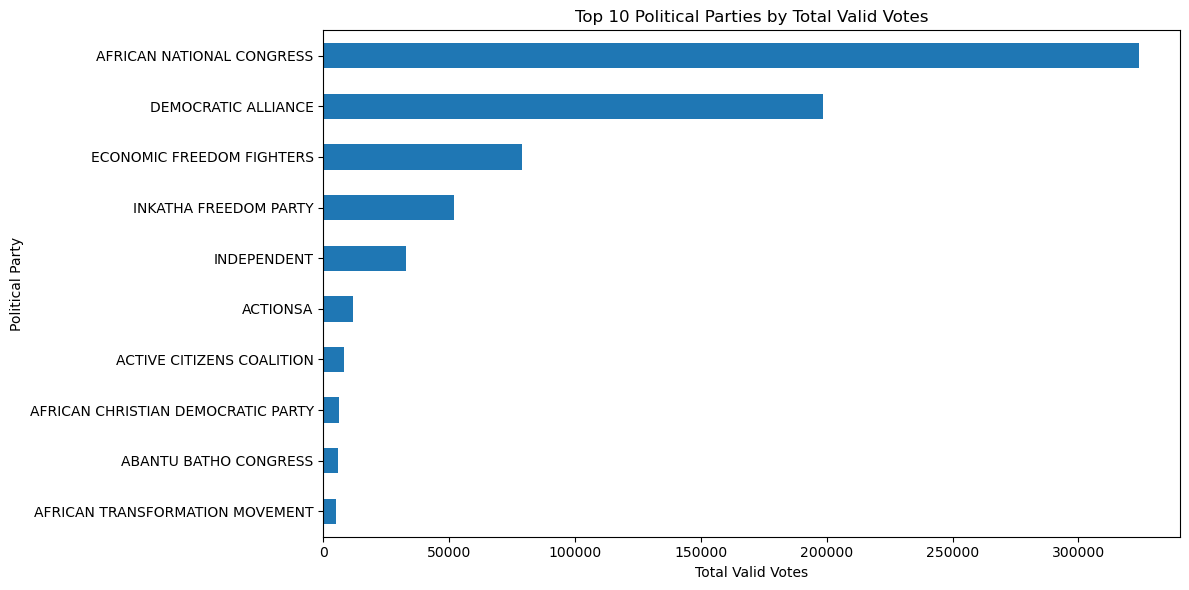

In [122]:
plt.figure(figsize=(12, 6))

top_10_parties.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Political Parties by Total Valid Votes")
plt.xlabel("Total Valid Votes")
plt.ylabel("Political Party")

plt.tight_layout()
plt.show()

### Interpretation

The bar chart compares the ten political parties that received the highest number of valid votes in the dataset.

Parties with longer bars received more votes than parties with shorter bars.

The visualisation makes it easier to identify the dominant political parties in the eThekwini Municipality and compare their overall election performance.

## 3. Vote Percentage of the Top 10 Political Parties

Total votes provide useful information about political party performance, but percentages make comparisons easier.

The percentage of votes received by each of the top ten political parties is calculated relative to the total valid votes represented in the dataset.

In [123]:
top_10_percentage = (
    top_10_parties / party_votes.sum()
) * 100

top_10_percentage = top_10_percentage.round(2)

top_10_percentage

PartyName
AFRICAN NATIONAL CONGRESS             41.77
DEMOCRATIC ALLIANCE                   25.57
ECONOMIC FREEDOM FIGHTERS             10.15
INKATHA FREEDOM PARTY                  6.67
INDEPENDENT                            4.25
ACTIONSA                               1.50
ACTIVE CITIZENS COALITION              1.03
AFRICAN CHRISTIAN DEMOCRATIC PARTY     0.78
ABANTU BATHO CONGRESS                  0.76
AFRICAN TRANSFORMATION MOVEMENT        0.66
Name: TotalValidVotes, dtype: float64

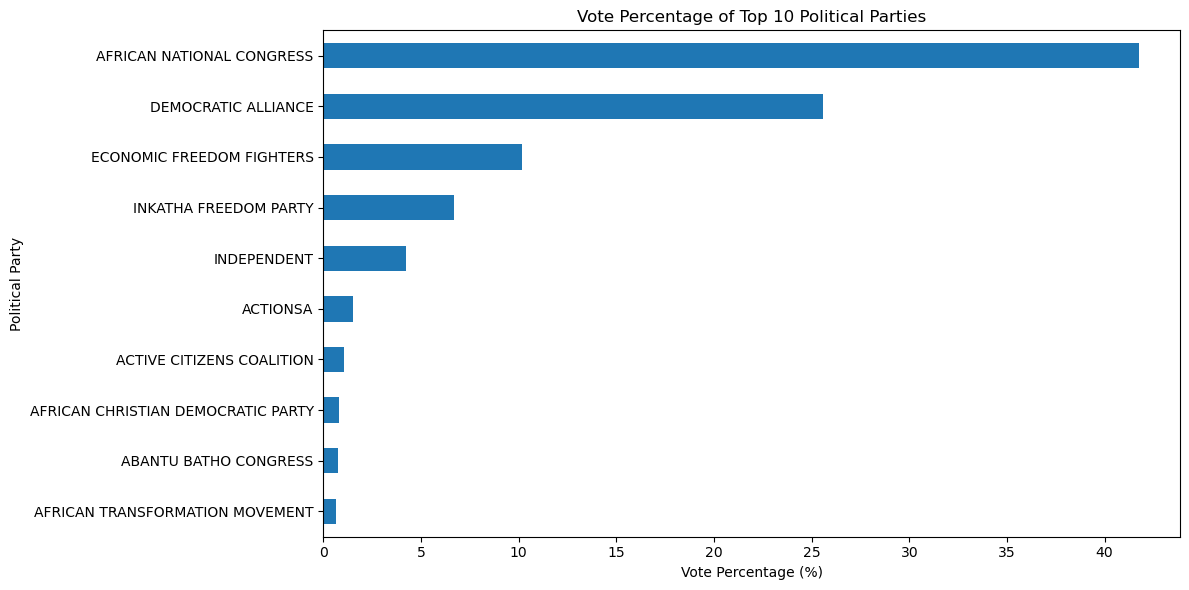

In [124]:
plt.figure(figsize=(12, 6))

top_10_percentage.sort_values().plot(
    kind="barh"
)

plt.title("Vote Percentage of Top 10 Political Parties")
plt.xlabel("Vote Percentage (%)")
plt.ylabel("Political Party")

plt.tight_layout()
plt.show()

### Interpretation

The graph shows the percentage contribution of each of the top ten political parties to the total valid votes.

Vote percentages allow political parties to be compared independently of the raw number of votes.

A higher percentage indicates stronger overall electoral support within the dataset.

## 4. Registered Voters by Ward

The number of registered voters differs between wards.

To avoid counting the same registered voters multiple times, the voting-district-level dataset created during data cleaning is used.

Registered voters are grouped by ward to determine which wards contain the largest registered voter populations.

In [125]:
registered_by_ward = (
    district_voters
    .groupby("Ward")["RegisteredVoters"]
    .sum()
    .sort_values(ascending=False)
)

registered_by_ward.head(10)

Ward
Ward 59500029    22962
Ward 59500065    20450
Ward 59500010    19912
Ward 59500056    19783
Ward 59500004    19776
Ward 59500031    19694
Ward 59500011    19677
Ward 59500059    19645
Ward 59500060    19601
Ward 59500016    19531
Name: RegisteredVoters, dtype: int64

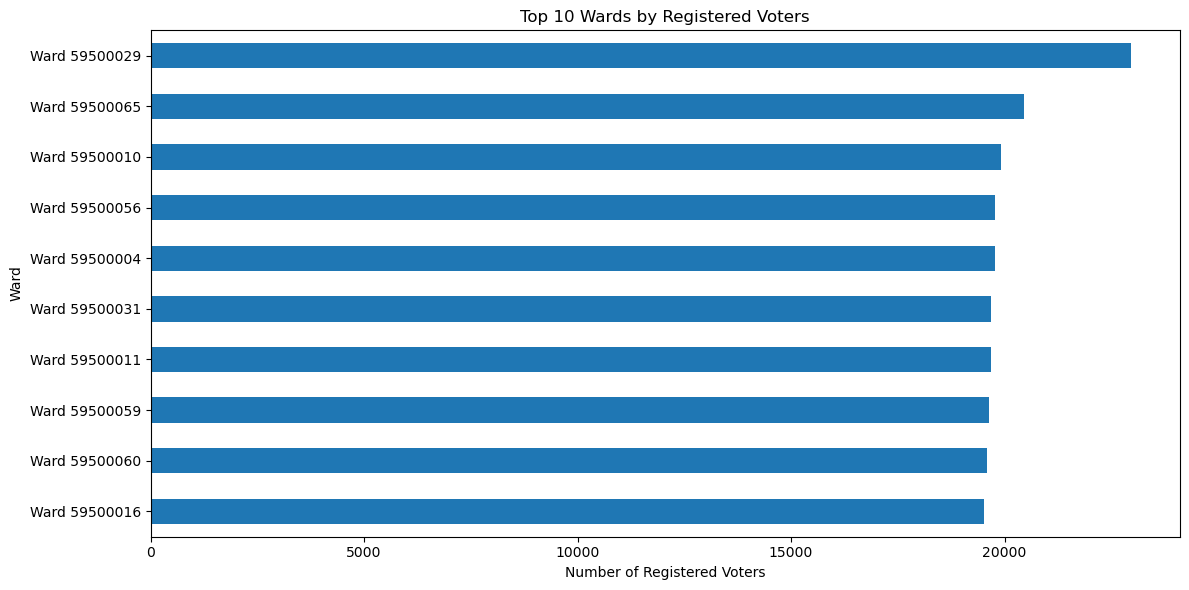

In [126]:
top_10_registered_wards = registered_by_ward.head(10)

plt.figure(figsize=(12, 6))

top_10_registered_wards.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Wards by Registered Voters")
plt.xlabel("Number of Registered Voters")
plt.ylabel("Ward")

plt.tight_layout()
plt.show()

### Interpretation

The graph displays the ten wards with the largest number of registered voters.

Differences between wards may be influenced by population size and the number of voting districts within each ward.

Wards with larger registered voter populations can potentially contribute a larger number of votes to the overall municipal election result.

## 5. Total Valid Votes by Ward

The total number of valid votes recorded in each ward is analysed to understand where the largest volumes of votes were recorded.

Election records are grouped according to ward and the valid votes are added together.

In [127]:
votes_by_ward = (
    df.groupby("Ward")["TotalValidVotes"]
    .sum()
    .sort_values(ascending=False)
)

votes_by_ward.head(10)

Ward
Ward 59500010    11380
Ward 59500001    10381
Ward 59500009    10043
Ward 59500035     9698
Ward 59500008     9683
Ward 59500050     9350
Ward 59500036     9349
Ward 59500049     9274
Ward 59500103     9251
Ward 59500065     9230
Name: TotalValidVotes, dtype: int64

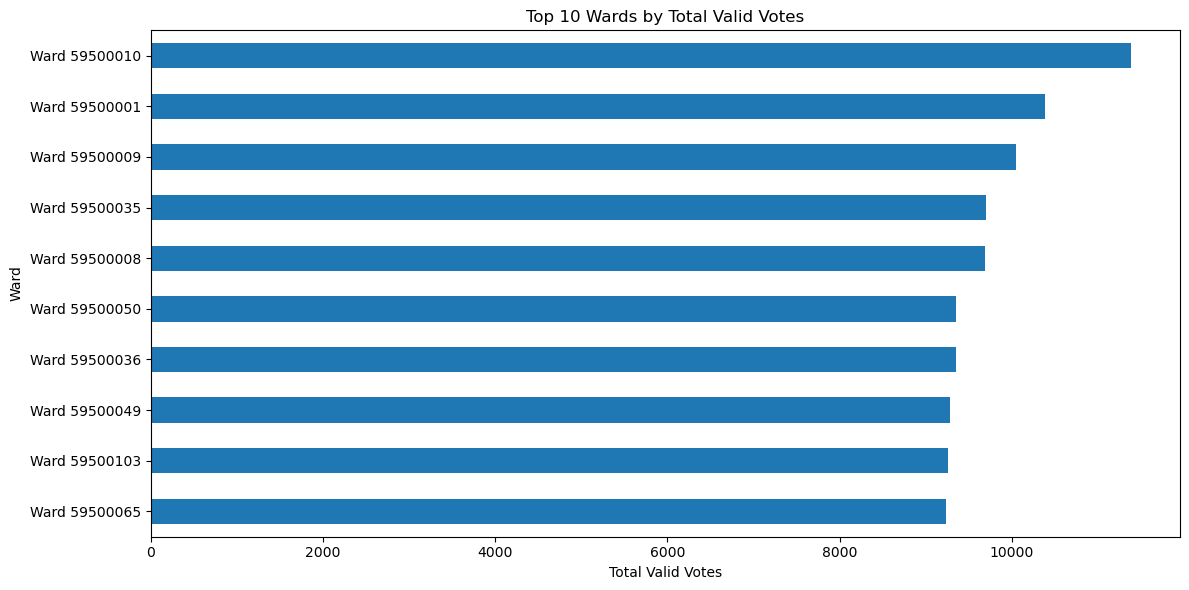

In [128]:
top_10_voting_wards = votes_by_ward.head(10)

plt.figure(figsize=(12, 6))

top_10_voting_wards.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Wards by Total Valid Votes")
plt.xlabel("Total Valid Votes")
plt.ylabel("Ward")

plt.tight_layout()
plt.show()

### Interpretation

The graph identifies the wards with the highest number of valid votes recorded in the dataset.

Comparing this result with registered voter numbers can help determine whether wards with larger registered populations also produce larger numbers of valid votes.

## 6. Winning Political Party by Ward

Overall municipal results do not show how political support differs geographically.

To investigate local voting patterns, the total valid votes received by each political party are calculated separately for each ward.

The political party receiving the highest number of votes within each ward is then identified as the leading party for that ward.

In [129]:
ward_party_votes = (
    df.groupby(["Ward", "PartyName"])["TotalValidVotes"]
    .sum()
    .reset_index()
)

ward_party_votes.head()

,Ward,PartyName,TotalValidVotes
0,Ward 59500001,ABANTU BATHO CONGRESS,304
1,Ward 59500001,ACADEMIC CONGRESS UNION,3
2,Ward 59500001,ACTIONSA,16
3,Ward 59500001,ACTIVISTS MOVEMENT OF SOUTH AFRICA,2
4,Ward 59500001,ADVANCED DYNAMIC ALLIANCE,3


In [130]:
winning_parties = ward_party_votes.loc[
    ward_party_votes.groupby("Ward")["TotalValidVotes"].idxmax()
]

winning_parties = winning_parties.sort_values(
    "Ward"
)

winning_parties.head(10)

,Ward,PartyName,TotalValidVotes
9,Ward 59500001,AFRICAN NATIONAL CONGRESS,9152
46,Ward 59500002,AFRICAN NATIONAL CONGRESS,7057
82,Ward 59500003,AFRICAN NATIONAL CONGRESS,4292
119,Ward 59500004,AFRICAN NATIONAL CONGRESS,6906
157,Ward 59500005,AFRICAN NATIONAL CONGRESS,3623
195,Ward 59500006,AFRICAN NATIONAL CONGRESS,5283
234,Ward 59500007,AFRICAN NATIONAL CONGRESS,3631
271,Ward 59500008,AFRICAN NATIONAL CONGRESS,4699
317,Ward 59500009,DEMOCRATIC ALLIANCE,3560
354,Ward 59500010,DEMOCRATIC ALLIANCE,9105


### Number of Wards Won by Each Political Party

After identifying the leading political party in each ward, the number of wards led by each party is calculated.

This provides a geographical measure of party performance rather than considering only the total number of votes.

In [131]:
wards_won = (
    winning_parties["PartyName"]
    .value_counts()
)

wards_won

PartyName
AFRICAN NATIONAL CONGRESS    75
DEMOCRATIC ALLIANCE          34
INKATHA FREEDOM PARTY         2
Name: count, dtype: int64

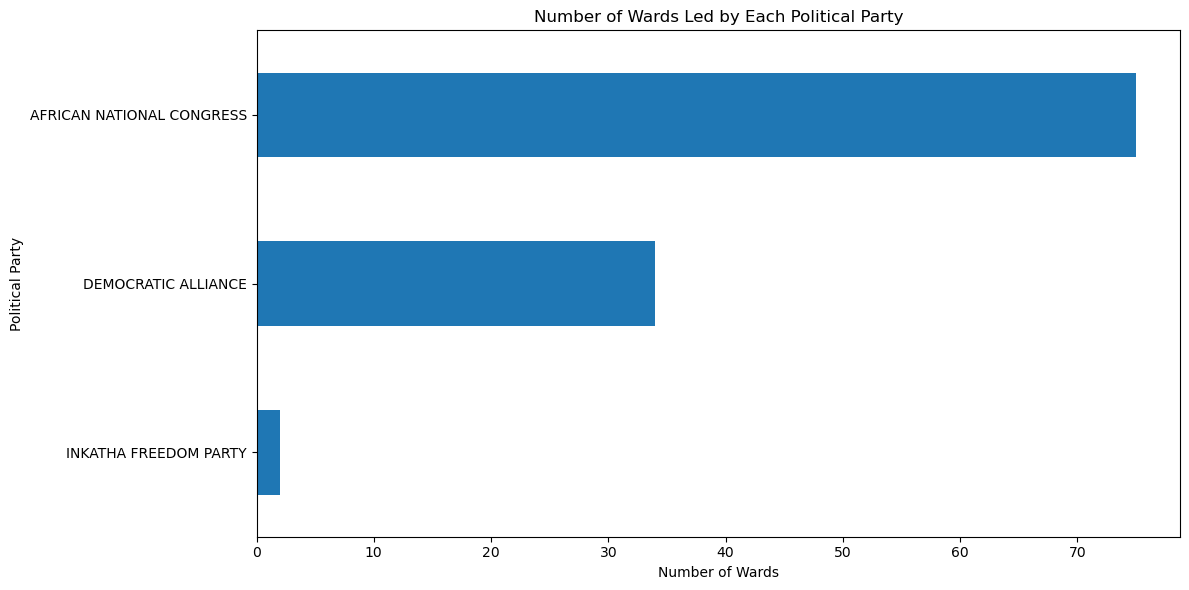

In [132]:
plt.figure(figsize=(12, 6))

wards_won.sort_values().plot(
    kind="barh"
)

plt.title("Number of Wards Led by Each Political Party")
plt.xlabel("Number of Wards")
plt.ylabel("Political Party")

plt.tight_layout()
plt.show()

### Interpretation

This graph shows how many wards are led by each political party based on the election results contained in the dataset.

This analysis provides additional insight into geographical political support.

A political party may receive a large number of votes overall while another party may demonstrate strong support within specific wards. Therefore, ward-level analysis provides more detailed information than municipal totals alone.

## 7. Voting Stations with the Highest Number of Valid Votes

Voting station analysis provides a more detailed geographical view of election participation.

The total valid votes recorded at each voting station are calculated and the ten voting stations with the largest number of valid votes are identified.

In [133]:
votes_by_station = (
    df.groupby("VotingStationName")["TotalValidVotes"]
    .sum()
    .sort_values(ascending=False)
)

top_10_stations = votes_by_station.head(10)

top_10_stations

VotingStationName
WATERFALL LIBRARY ACTIVITIES ROOM    3754
HILLCREST HIGH SCHOOL                3558
NG KERK UMHLANGA                     2826
AMANZIMTOTI CIVIC-CENTRE             2687
CHELSEA PREPARATORY SCHOOL           2595
COWIES HILL COMMUNITY HALL           2442
UMKHUMBANE WIGGINS COMMUNITY HALL    2430
ZWELITSHA COMMUNITY HALL             2406
KWACUTSHWAYO PRIMARY SCHOOL          2396
MT MORIA SITE OFFICE                 2325
Name: TotalValidVotes, dtype: int64

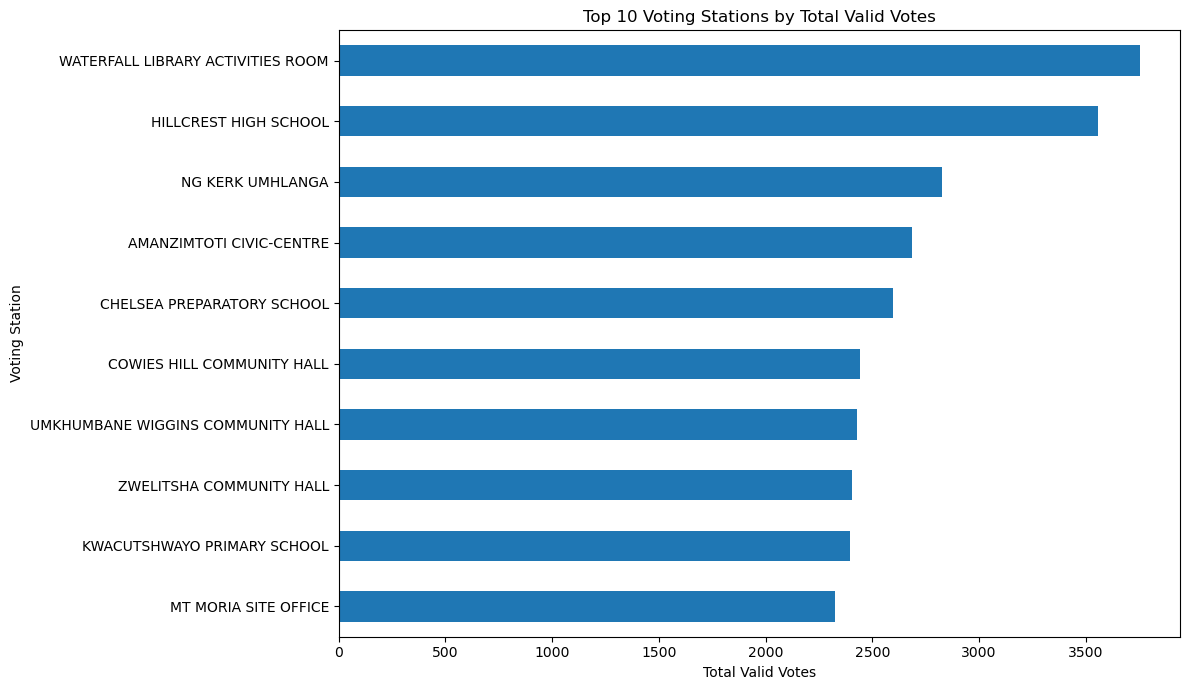

In [134]:
plt.figure(figsize=(12, 7))

top_10_stations.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Voting Stations by Total Valid Votes")
plt.xlabel("Total Valid Votes")
plt.ylabel("Voting Station")

plt.tight_layout()
plt.show()

### Interpretation

The graph identifies the voting stations where the largest numbers of valid votes were recorded.

Differences between voting stations may be influenced by the number of registered voters, location and voter participation.

Voting-station-level analysis can help identify areas with particularly high election activity.

## 8. Distribution of Valid Votes

A histogram is used to examine how TotalValidVotes values are distributed throughout the dataset.

This helps determine whether most party-level records contain small, medium or large numbers of votes and can also reveal unusual values.

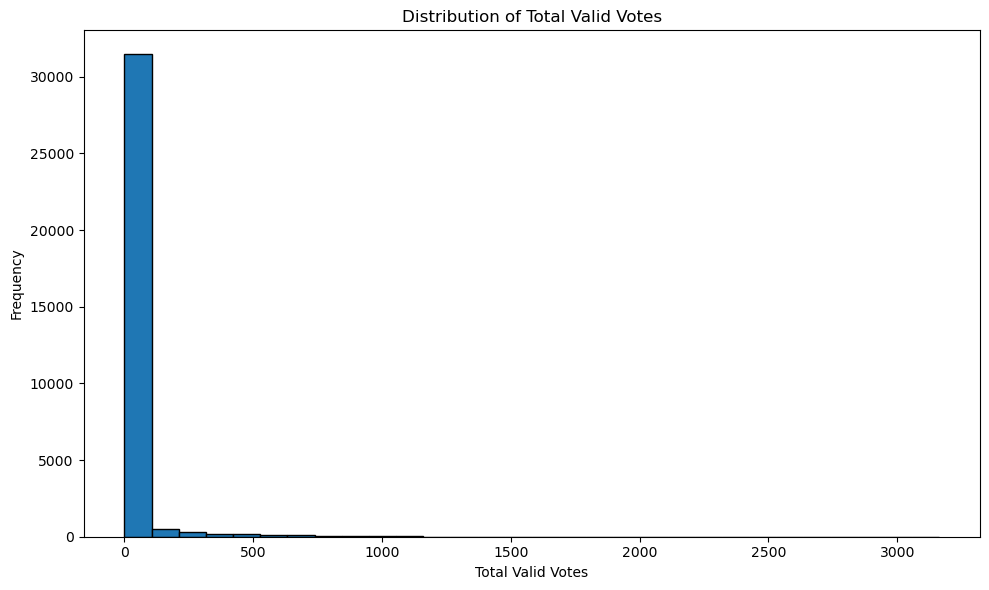

In [135]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["TotalValidVotes"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Total Valid Votes")
plt.xlabel("Total Valid Votes")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Interpretation

The histogram shows the distribution of valid votes across the election records.

Election datasets often contain many records with relatively small vote counts because several political parties compete within each voting area.

Larger vote values occur less frequently and may represent political parties with stronger support in particular voting areas.

## 9. Relationship Between Registered Voters and Valid Votes

The relationship between registered voters and the number of valid votes is important when analysing election participation.

A voting-district-level dataset is created by calculating the total valid votes recorded within each voting district.

This is then compared with the number of registered voters in the same voting district.

In [136]:
district_votes = (
    df.groupby("VotingDistrict")["TotalValidVotes"]
    .sum()
    .reset_index()
)

district_analysis = district_voters.merge(
    district_votes,
    on="VotingDistrict"
)

district_analysis.head()

,VotingDistrict,VotingStationName,Ward,RegisteredVoters,TotalValidVotes
0,43400179,NOMFIHLELA PRIMARY SCHOOL,Ward 59500001,2365,970
1,43400180,OTHWEBA PRIMARY SCHOOL,Ward 59500001,1569,962
2,43400191,GEORGE CATO PRIMARY SCHOOL,Ward 59500001,866,344
3,43400528,NGIDI PRIMARY SCHOOL,Ward 59500001,1890,980
4,43400539,MVINI PRIMARY SCHOOL,Ward 59500001,1631,1055


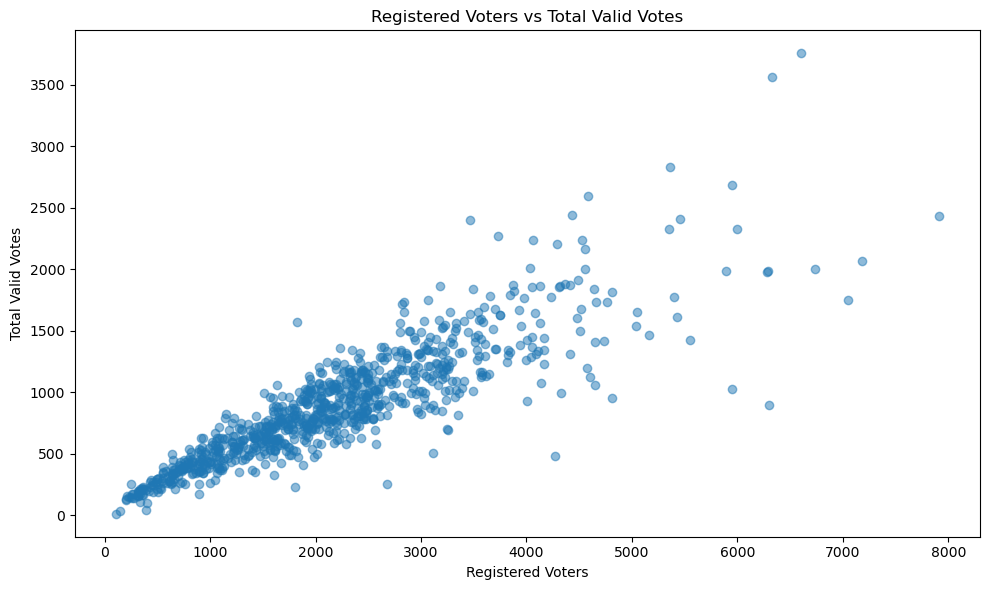

In [137]:
plt.figure(figsize=(10, 6))

plt.scatter(
    district_analysis["RegisteredVoters"],
    district_analysis["TotalValidVotes"],
    alpha=0.5
)

plt.title("Registered Voters vs Total Valid Votes")
plt.xlabel("Registered Voters")
plt.ylabel("Total Valid Votes")

plt.tight_layout()
plt.show()

### Interpretation

The scatter plot compares the number of registered voters with the total valid votes recorded in each voting district.

An upward pattern would suggest that voting districts with more registered voters generally record more valid votes.

However, registered voters and actual votes are not the same measurement. Not every registered voter necessarily participates in an election, which is why voter participation should be examined separately.

## 10. Correlation Between Registered Voters and Valid Votes

Correlation measures the strength of the relationship between two numerical variables.

A correlation value close to 1 indicates a strong positive relationship, while a value close to 0 indicates a weak linear relationship.

The correlation between registered voters and total valid votes is calculated below.

In [138]:
correlation = district_analysis[
    ["RegisteredVoters", "TotalValidVotes"]
].corr()

correlation

,RegisteredVoters,TotalValidVotes
RegisteredVoters,1.000000,0.875255
TotalValidVotes,0.875255,1.000000


In [139]:
correlation_value = district_analysis[
    "RegisteredVoters"
].corr(
    district_analysis["TotalValidVotes"]
)

print(
    "Correlation between Registered Voters and Total Valid Votes:",
    round(correlation_value, 3)
)

Correlation between Registered Voters and Total Valid Votes: 0.875


### Interpretation

The correlation result indicates the strength of the relationship between registered voters and valid votes.

A positive correlation would indicate that voting districts with larger registered voter populations generally record more valid votes.

The strength of this relationship will help determine whether registered voter information may be useful as an input variable during the machine learning stage.

## 11. Election Analysis Summary

A summary table is created for the highest-performing political parties.

The table contains the total number of valid votes received by each party and its percentage contribution to the total valid votes represented in the dataset.

In [140]:
party_summary.head(10)

,TotalVotes,VotePercentage
PartyName,,
AFRICAN NATIONAL CONGRESS,324137,41.77
DEMOCRATIC ALLIANCE,198433,25.57
ECONOMIC FREEDOM FIGHTERS,78748,10.15
INKATHA FREEDOM PARTY,51725,6.67
INDEPENDENT,32987,4.25
ACTIONSA,11663,1.50
ACTIVE CITIZENS COALITION,8025,1.03
AFRICAN CHRISTIAN DEMOCRATIC PARTY,6022,0.78
ABANTU BATHO CONGRESS,5866,0.76


In [141]:
top_party_summary = party_summary.head(10).copy()

top_party_summary

,TotalVotes,VotePercentage
PartyName,,
AFRICAN NATIONAL CONGRESS,324137,41.77
DEMOCRATIC ALLIANCE,198433,25.57
ECONOMIC FREEDOM FIGHTERS,78748,10.15
INKATHA FREEDOM PARTY,51725,6.67
INDEPENDENT,32987,4.25
ACTIONSA,11663,1.50
ACTIVE CITIZENS COALITION,8025,1.03
AFRICAN CHRISTIAN DEMOCRATIC PARTY,6022,0.78
ABANTU BATHO CONGRESS,5866,0.76


## 12. Exploratory Data Analysis Summary

The exploratory data analysis provided insight into voting patterns within the eThekwini Municipality.

Political party performance was analysed using total valid votes and vote percentages. The analysis also examined registered voters across wards, total valid votes across wards, voting station activity and the political parties leading in individual wards.

The ward-level analysis demonstrated that overall municipal performance does not necessarily explain geographical voting patterns. Analysing individual wards provides a clearer understanding of where political parties receive their strongest support.

The relationship between registered voters and valid votes was also investigated using a scatter plot and correlation analysis. This provides an indication of whether registered voter population may be useful when developing predictive models.

These exploratory findings provide the foundation for the next stage of the project, where the election data will be transformed and prepared for machine learning.

# Feature Engineering and Machine Learning Preparation

Machine learning requires data to be organised into suitable input features and a target variable.

The raw election dataset contains information at political party and voting district level. Therefore, the data must first be transformed into a structure that can be used by a machine learning algorithm.

In this section, the following tasks are performed:

- Define the machine learning problem
- Create ward and political party level features
- Identify the target variable
- Select suitable predictor variables
- Check the distribution of the target variable
- Encode categorical variables
- Separate features and target variables
- Split the dataset into training and testing sets

The prepared data will later be used to train and evaluate machine learning models.

## 4.1 Defining the Machine Learning Problem

The objective of the machine learning component is to predict the leading political party based on election-related information.

This is a classification problem because the output belongs to a category, namely a political party.

For the initial model, historical election information will be used to investigate whether patterns in registered voters, ward information and party-level election performance can be learned by a machine learning algorithm.

It is important to distinguish between analysing historical election results and forecasting a genuinely future election. A reliable future-election forecast normally requires election results from multiple historical election periods. The current model will therefore first focus on learning patterns within the available historical dataset.

## 4.2 Creating Ward-Party Level Data

The original dataset contains multiple records for political parties across voting districts.

For machine learning, the data is aggregated to ward and political party level.

The total valid votes received by each political party within each ward are calculated. This creates a simpler dataset that represents party performance across wards.

In [142]:
ward_party_ml = (
    df.groupby(["Ward", "PartyName"])
    .agg(
        TotalValidVotes=("TotalValidVotes", "sum")
    )
    .reset_index()
)

ward_party_ml.head()

,Ward,PartyName,TotalValidVotes
0,Ward 59500001,ABANTU BATHO CONGRESS,304
1,Ward 59500001,ACADEMIC CONGRESS UNION,3
2,Ward 59500001,ACTIONSA,16
3,Ward 59500001,ACTIVISTS MOVEMENT OF SOUTH AFRICA,2
4,Ward 59500001,ADVANCED DYNAMIC ALLIANCE,3


In [143]:
print("Number of rows:", ward_party_ml.shape[0])
print("Number of columns:", ward_party_ml.shape[1])

ward_party_ml.head(10)

Number of rows: 4191
Number of columns: 3


,Ward,PartyName,TotalValidVotes
0,Ward 59500001,ABANTU BATHO CONGRESS,304
1,Ward 59500001,ACADEMIC CONGRESS UNION,3
2,Ward 59500001,ACTIONSA,16
3,Ward 59500001,ACTIVISTS MOVEMENT OF SOUTH AFRICA,2
4,Ward 59500001,ADVANCED DYNAMIC ALLIANCE,3
5,Ward 59500001,AFRICA RESTORATION ALLIANCE,3
6,Ward 59500001,AFRICAN CHRISTIAN DEMOCRATIC PARTY,16
7,Ward 59500001,AFRICAN DEMOCRATIC CHANGE,0
8,Ward 59500001,AFRICAN MANTUNGWA COMMUNITY,17
9,Ward 59500001,AFRICAN NATIONAL CONGRESS,9152


## 4.3 Adding Registered Voter Information

Registered voter information may provide useful information about the potential size of the electorate within each ward.

Because registered voter values are repeated across political party records in the original dataset, registered voters are first calculated using the unique voting-district-level dataset created during data cleaning.

The total number of registered voters is then calculated for each ward.

In [144]:
ward_registered = (
    district_voters
    .groupby("Ward")["RegisteredVoters"]
    .sum()
    .reset_index()
)

ward_registered.head()

,Ward,RegisteredVoters
0,Ward 59500001,18289
1,Ward 59500002,18664
2,Ward 59500003,15086
3,Ward 59500004,19776
4,Ward 59500005,14605


In [145]:
ward_party_ml = ward_party_ml.merge(
    ward_registered,
    on="Ward",
    how="left"
)

ward_party_ml.head()

,Ward,PartyName,TotalValidVotes,RegisteredVoters
0,Ward 59500001,ABANTU BATHO CONGRESS,304,18289
1,Ward 59500001,ACADEMIC CONGRESS UNION,3,18289
2,Ward 59500001,ACTIONSA,16,18289
3,Ward 59500001,ACTIVISTS MOVEMENT OF SOUTH AFRICA,2,18289
4,Ward 59500001,ADVANCED DYNAMIC ALLIANCE,3,18289


## 4. Number of Voting Districts per Ward

The number of voting districts within a ward provides additional information about the geographical structure of the ward.

This variable is calculated and added to the machine learning dataset as another potential predictor.

In [146]:
districts_per_ward = (
    district_voters
    .groupby("Ward")["VotingDistrict"]
    .nunique()
    .reset_index(name="NumberOfVotingDistricts")
)

districts_per_ward.head()

,Ward,NumberOfVotingDistricts
0,Ward 59500001,12
1,Ward 59500002,22
2,Ward 59500003,13
3,Ward 59500004,10
4,Ward 59500005,5


In [147]:
ward_party_ml = ward_party_ml.merge(
    districts_per_ward,
    on="Ward",
    how="left"
)

ward_party_ml.head()

,Ward,PartyName,TotalValidVotes,RegisteredVoters,NumberOfVotingDistricts
0,Ward 59500001,ABANTU BATHO CONGRESS,304,18289,12
1,Ward 59500001,ACADEMIC CONGRESS UNION,3,18289,12
2,Ward 59500001,ACTIONSA,16,18289,12
3,Ward 59500001,ACTIVISTS MOVEMENT OF SOUTH AFRICA,2,18289,12
4,Ward 59500001,ADVANCED DYNAMIC ALLIANCE,3,18289,12


## 5. Creating Party Vote Share

Raw vote totals can be difficult to compare because wards may contain different numbers of voters.

A PartyVoteShare feature is therefore created.

Party vote share represents the percentage of valid votes within a ward that were received by a particular political party.

This variable provides a standardised measure of political party performance.

In [148]:
ward_totals = (
    ward_party_ml
    .groupby("Ward")["TotalValidVotes"]
    .transform("sum")
)

ward_party_ml["PartyVoteShare"] = (
    ward_party_ml["TotalValidVotes"] / ward_totals
) * 100

ward_party_ml.head()

,Ward,PartyName,TotalValidVotes,RegisteredVoters,NumberOfVotingDistricts,PartyVoteShare
0,Ward 59500001,ABANTU BATHO CONGRESS,304,18289,12,2.928427
1,Ward 59500001,ACADEMIC CONGRESS UNION,3,18289,12,0.028899
2,Ward 59500001,ACTIONSA,16,18289,12,0.154128
3,Ward 59500001,ACTIVISTS MOVEMENT OF SOUTH AFRICA,2,18289,12,0.019266
4,Ward 59500001,ADVANCED DYNAMIC ALLIANCE,3,18289,12,0.028899


In [149]:
ward_party_ml["PartyVoteShare"] = (
    ward_party_ml["PartyVoteShare"].round(2)
)

ward_party_ml.head(10)

,Ward,PartyName,TotalValidVotes,RegisteredVoters,NumberOfVotingDistricts,PartyVoteShare
0,Ward 59500001,ABANTU BATHO CONGRESS,304,18289,12,2.93
1,Ward 59500001,ACADEMIC CONGRESS UNION,3,18289,12,0.03
2,Ward 59500001,ACTIONSA,16,18289,12,0.15
3,Ward 59500001,ACTIVISTS MOVEMENT OF SOUTH AFRICA,2,18289,12,0.02
4,Ward 59500001,ADVANCED DYNAMIC ALLIANCE,3,18289,12,0.03
5,Ward 59500001,AFRICA RESTORATION ALLIANCE,3,18289,12,0.03
6,Ward 59500001,AFRICAN CHRISTIAN DEMOCRATIC PARTY,16,18289,12,0.15
7,Ward 59500001,AFRICAN DEMOCRATIC CHANGE,0,18289,12,0.00
8,Ward 59500001,AFRICAN MANTUNGWA COMMUNITY,17,18289,12,0.16
9,Ward 59500001,AFRICAN NATIONAL CONGRESS,9152,18289,12,88.16


## 6. Creating the Target Variable

The target variable represents the outcome that the machine learning model will attempt to predict.

For this analysis, the target variable is called `Winner`.

A value of:

- `1` indicates that the political party received the highest number of valid votes in that ward.
- `0` indicates that the political party did not receive the highest number of valid votes in that ward.

This converts the election outcome into a binary classification problem.

In [150]:
max_votes_per_ward = (
    ward_party_ml
    .groupby("Ward")["TotalValidVotes"]
    .transform("max")
)

In [151]:
ward_party_ml["Winner"] = (
    ward_party_ml["TotalValidVotes"]
    == max_votes_per_ward
).astype(int)

ward_party_ml.head(10)

,Ward,PartyName,TotalValidVotes,RegisteredVoters,NumberOfVotingDistricts,PartyVoteShare,Winner
0,Ward 59500001,ABANTU BATHO CONGRESS,304,18289,12,2.93,0
1,Ward 59500001,ACADEMIC CONGRESS UNION,3,18289,12,0.03,0
2,Ward 59500001,ACTIONSA,16,18289,12,0.15,0
3,Ward 59500001,ACTIVISTS MOVEMENT OF SOUTH AFRICA,2,18289,12,0.02,0
4,Ward 59500001,ADVANCED DYNAMIC ALLIANCE,3,18289,12,0.03,0
5,Ward 59500001,AFRICA RESTORATION ALLIANCE,3,18289,12,0.03,0
6,Ward 59500001,AFRICAN CHRISTIAN DEMOCRATIC PARTY,16,18289,12,0.15,0
7,Ward 59500001,AFRICAN DEMOCRATIC CHANGE,0,18289,12,0.00,0
8,Ward 59500001,AFRICAN MANTUNGWA COMMUNITY,17,18289,12,0.16,0
9,Ward 59500001,AFRICAN NATIONAL CONGRESS,9152,18289,12,88.16,1


## 7 Checking the Target Variable

The newly created Winner variable is examined to determine the number of winning and non-winning party records.

Understanding the distribution of the target variable is important because highly unbalanced classes can affect machine learning model performance.

In [152]:
print(
    ward_party_ml["Winner"].value_counts()
)

Winner
0    4080
1     111
Name: count, dtype: int64


In [153]:
winner_percentage = (
    ward_party_ml["Winner"]
    .value_counts(normalize=True)
    * 100
)

print(winner_percentage.round(2))

Winner
0    97.35
1     2.65
Name: proportion, dtype: float64


## 8 Target Variable Distribution

A bar chart is used to visualise the distribution of winning and non-winning party records.

This helps identify whether the machine learning dataset contains class imbalance.

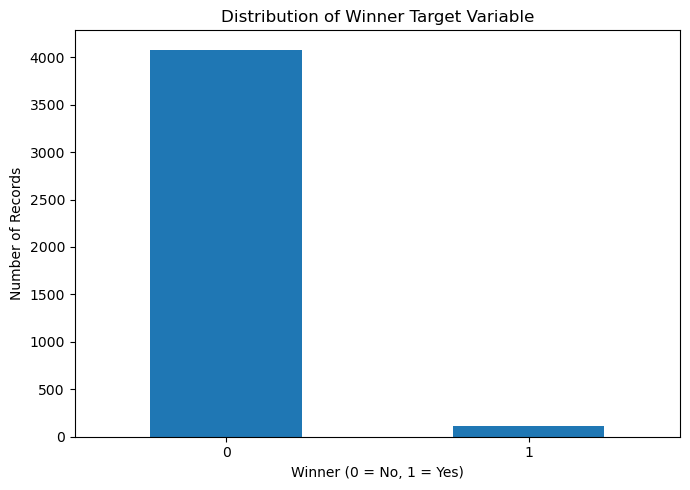

In [154]:
winner_counts = (
    ward_party_ml["Winner"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7, 5))

winner_counts.plot(kind="bar")

plt.title("Distribution of Winner Target Variable")
plt.xlabel("Winner (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Interpretation

The target variable is expected to be imbalanced because several political parties may compete within a ward while only one party normally receives the highest number of votes.

Therefore, the number of non-winning records is considerably larger than the number of winning records.

This class imbalance must be considered when evaluating the machine learning models. Accuracy alone may not provide a complete measure of model performance, so additional metrics such as precision, recall, F1-score and the confusion matrix will also be considered.

## 9 Checking the Prepared Dataset for Missing Values

After merging and creating new variables, the machine learning dataset is checked again for missing values.

Machine learning algorithms generally require complete input data, so missing values must be identified before model training.

In [155]:
print(ward_party_ml.isnull().sum())

Ward                       0
PartyName                  0
TotalValidVotes            0
RegisteredVoters           0
NumberOfVotingDistricts    0
PartyVoteShare             0
Winner                     0
dtype: int64


In [156]:
ward_party_ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4191 entries, 0 to 4190
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Ward                     4191 non-null   object 
 1   PartyName                4191 non-null   object 
 2   TotalValidVotes          4191 non-null   int64  
 3   RegisteredVoters         4191 non-null   int64  
 4   NumberOfVotingDistricts  4191 non-null   int64  
 5   PartyVoteShare           4191 non-null   float64
 6   Winner                   4191 non-null   int64  
dtypes: float64(1), int64(4), object(2)
memory usage: 229.3+ KB


## 10 Reviewing the Machine Learning Dataset

The prepared dataset is reviewed before selecting the predictor and target variables.

This ensures that the newly engineered features were created correctly and that the dataset is ready for machine learning.

In [157]:
ward_party_ml.head(20)

,Ward,PartyName,TotalValidVotes,RegisteredVoters,NumberOfVotingDistricts,PartyVoteShare,Winner
0,Ward 59500001,ABANTU BATHO CONGRESS,304,18289,12,2.93,0
1,Ward 59500001,ACADEMIC CONGRESS UNION,3,18289,12,0.03,0
2,Ward 59500001,ACTIONSA,16,18289,12,0.15,0
3,Ward 59500001,ACTIVISTS MOVEMENT OF SOUTH AFRICA,2,18289,12,0.02,0
4,Ward 59500001,ADVANCED DYNAMIC ALLIANCE,3,18289,12,0.03,0
5,Ward 59500001,AFRICA RESTORATION ALLIANCE,3,18289,12,0.03,0
6,Ward 59500001,AFRICAN CHRISTIAN DEMOCRATIC PARTY,16,18289,12,0.15,0
7,Ward 59500001,AFRICAN DEMOCRATIC CHANGE,0,18289,12,0.00,0
8,Ward 59500001,AFRICAN MANTUNGWA COMMUNITY,17,18289,12,0.16,0
9,Ward 59500001,AFRICAN NATIONAL CONGRESS,9152,18289,12,88.16,1


In [158]:
print("Dataset shape:", ward_party_ml.shape)

print("\nColumns:")
print(ward_party_ml.columns)

Dataset shape: (4191, 7)

Columns:
Index(['Ward', 'PartyName', 'TotalValidVotes', 'RegisteredVoters',
       'NumberOfVotingDistricts', 'PartyVoteShare', 'Winner'],
      dtype='object')


## 11. Preventing Data Leakage

Data leakage occurs when information that directly reveals the target outcome is included as an input to the machine learning model.

The Winner variable was created using TotalValidVotes. Therefore, using TotalValidVotes or PartyVoteShare as predictor variables when predicting Winner would allow the model to indirectly see the election result that it is supposed to predict.

This would produce unrealistically high model performance.

To create a more meaningful model, variables that directly reveal the final election outcome should be excluded from the predictor variables when appropriate.

## 12. Encoding Political Party Names

The PartyName variable contains categorical text values.

Most machine learning algorithms require numerical input. Therefore, political party names are converted into numerical values using Label Encoding.

Each political party is assigned a numerical code that can be processed by the machine learning algorithms.

In [159]:
from sklearn.preprocessing import LabelEncoder

party_encoder = LabelEncoder()

ward_party_ml["PartyEncoded"] = (
    party_encoder.fit_transform(
        ward_party_ml["PartyName"]
    )
)

ward_party_ml[
    ["PartyName", "PartyEncoded"]
].head(20)

,PartyName,PartyEncoded
0,ABANTU BATHO CONGRESS,0
1,ACADEMIC CONGRESS UNION,1
2,ACTIONSA,2
3,ACTIVISTS MOVEMENT OF SOUTH AFRICA,4
4,ADVANCED DYNAMIC ALLIANCE,5
5,AFRICA RESTORATION ALLIANCE,6
6,AFRICAN CHRISTIAN DEMOCRATIC PARTY,7
7,AFRICAN DEMOCRATIC CHANGE,8
8,AFRICAN MANTUNGWA COMMUNITY,12
9,AFRICAN NATIONAL CONGRESS,13


## 13. Encoding Ward Information

Ward identifiers are also converted into numerical values so that they can be included in the machine learning dataset.

A separate encoder is used for the Ward variable.

In [160]:
ward_encoder = LabelEncoder()

ward_party_ml["WardEncoded"] = (
    ward_encoder.fit_transform(
        ward_party_ml["Ward"]
    )
)

ward_party_ml[
    ["Ward", "WardEncoded"]
].head()

,Ward,WardEncoded
0,Ward 59500001,0
1,Ward 59500001,0
2,Ward 59500001,0
3,Ward 59500001,0
4,Ward 59500001,0


## 14. Selecting Features and Target Variable

Machine learning data is normally separated into:

- `X` – the predictor or input variables
- `y` – the target variable that the model attempts to predict

For the initial classification experiment, the target variable is Winner.

Features that directly reveal the final election result, such as TotalValidVotes and PartyVoteShare, are excluded from the initial predictor set to reduce data leakage.

In [161]:
features = [
    "RegisteredVoters",
    "NumberOfVotingDistricts",
    "PartyEncoded",
    "WardEncoded"
]

X = ward_party_ml[features]

y = ward_party_ml["Winner"]

In [162]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (4191, 4)
y shape: (4191,)


,RegisteredVoters,NumberOfVotingDistricts,PartyEncoded,WardEncoded
0,18289,12,0,0
1,18289,12,1,0
2,18289,12,2,0
3,18289,12,4,0
4,18289,12,5,0


## 4.15 Splitting the Dataset into Training and Testing Sets

The machine learning dataset is divided into training and testing data.

The training dataset is used to teach the machine learning model, while the testing dataset is used to evaluate how well the trained model performs on unseen records.

For this project:

- 80% of the data is used for training.
- 20% of the data is used for testing.

A random state is specified to ensure that the same split can be reproduced.

Stratification is also used so that the proportion of winning and non-winning records remains similar in both datasets.

In [235]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [236]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (3352, 4)
Testing features: (839, 4)
Training target: (3352,)
Testing target: (839,)


In [237]:
print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training target distribution:
Winner
0    3263
1      89
Name: count, dtype: int64

Testing target distribution:
Winner
0    817
1     22
Name: count, dtype: int64


### Interpretation

The dataset has successfully been divided into training and testing subsets.

The larger training dataset will be used to train the machine learning algorithms, while the smaller testing dataset will be reserved for evaluating model performance.

Stratified sampling helps maintain a similar proportion of winning and non-winning records in both datasets.

In [238]:
print("Features used for Machine Learning:")
print(features)

print("\nX Training Preview:")
display(X_train.head())

print("\nTarget Preview:")
display(y_train.head())

Features used for Machine Learning:
['RegisteredVoters', 'NumberOfVotingDistricts', 'PartyEncoded', 'WardEncoded']

X Training Preview:


,RegisteredVoters,NumberOfVotingDistricts,PartyEncoded,WardEncoded
2285,19601,7,47,59
879,19057,6,17,23
335,18734,10,51,8
4074,13385,9,40,107
2658,17235,11,37,69



Target Preview:


2285    0
879     0
335     0
4074    0
2658    0
Name: Winner, dtype: int64

## 17. Feature Engineering Summary

The election dataset was successfully transformed into a format suitable for machine learning.

Election records were aggregated to ward and political party level. Additional features were created, including registered voters, number of voting districts and party vote share.

A binary target variable called Winner was created to identify whether a political party received the highest number of valid votes within a ward.

Categorical variables such as political party and ward were encoded into numerical values. Care was also taken to identify potential data leakage. TotalValidVotes and PartyVoteShare were therefore excluded from the initial predictor set because they directly reflect the election result used to determine the Winner variable.

Finally, the dataset was divided into training and testing subsets using an 80/20 split with stratification.

The prepared data can now be used to train and evaluate classification models.

#  Machine Learning Model Training and Evaluation

After preparing the election dataset, the next stage is to train and evaluate machine learning models.

Three classification algorithms are used in this project:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

The purpose is to determine which model performs best when predicting whether a political party will be the leading party within a ward.

The models are evaluated using several performance metrics, including:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix
- Classification Report

Using multiple evaluation metrics is important because the target variable is imbalanced, with considerably fewer winning records than non-winning records.

## 5.1 Importing Machine Learning Libraries

Scikit-learn provides several machine learning algorithms and evaluation tools.

The required classification models and performance metrics are imported before model training begins.

In [239]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


## 5.2 Logistic Regression

Logistic Regression is a supervised machine learning algorithm commonly used for classification problems.

In this project, Logistic Regression is used to predict whether a political party is a winner or non-winner within a ward.

The model is trained using the training dataset and then evaluated using the testing dataset.

In [240]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [241]:
logistic_predictions = logistic_model.predict(X_test)

print("Predictions completed!")

Predictions completed!


### Logistic Regression Performance

The Logistic Regression model is evaluated using accuracy, precision, recall and F1-score.

Accuracy measures the overall percentage of correct predictions.

Precision measures how often records predicted as winners are actually winners.

Recall measures how many of the actual winners were successfully identified by the model.

F1-score provides a balance between precision and recall.

In [242]:
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

logistic_precision = precision_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

logistic_recall = recall_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

logistic_f1 = f1_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print("Accuracy:", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall:", round(logistic_recall, 4))
print("F1 Score:", round(logistic_f1, 4))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.5447
Precision: 0.0431
Recall: 0.7727
F1 Score: 0.0817


In [243]:
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print("-----------------------------------------")

print(
    classification_report(
        y_test,
        logistic_predictions,
        zero_division=0
    )
)

LOGISTIC REGRESSION CLASSIFICATION REPORT
-----------------------------------------
              precision    recall  f1-score   support

           0       0.99      0.54      0.70       817
           1       0.04      0.77      0.08        22

    accuracy                           0.54       839
   macro avg       0.52      0.66      0.39       839
weighted avg       0.96      0.54      0.68       839



### Interpretation

The classification report provides detailed information about the performance of the Logistic Regression model for both target classes.

Class 0 represents non-winning political party records, while Class 1 represents winning political party records.

Because the dataset is imbalanced, particular attention should be given to the precision, recall and F1-score for Class 1. These values indicate how effectively the model identifies actual winning records.

### Logistic Regression Confusion Matrix

A confusion matrix provides a visual representation of correct and incorrect predictions.

The matrix contains:

- True Negatives: Non-winners correctly predicted as non-winners
- False Positives: Non-winners incorrectly predicted as winners
- False Negatives: Winners incorrectly predicted as non-winners
- True Positives: Winners correctly predicted as winners

A strong classification model should produce a large number of correct predictions along the main diagonal of the confusion matrix.

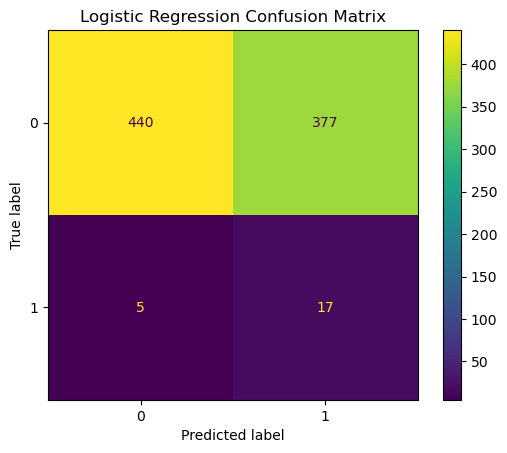

In [244]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

## 5.6 Decision Tree Classifier

A Decision Tree is a supervised machine learning algorithm that makes predictions by creating a series of decision rules based on the input features.

Decision Trees can capture more complex relationships than a simple linear model.

The model is trained using the same training dataset so that its performance can be compared fairly with Logistic Regression.

In [245]:
decision_tree_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

decision_tree_model.fit(
    X_train,
    y_train
)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [246]:
tree_predictions = decision_tree_model.predict(
    X_test
)

In [247]:
tree_accuracy = accuracy_score(
    y_test,
    tree_predictions
)

tree_precision = precision_score(
    y_test,
    tree_predictions,
    zero_division=0
)

tree_recall = recall_score(
    y_test,
    tree_predictions,
    zero_division=0
)

tree_f1 = f1_score(
    y_test,
    tree_predictions,
    zero_division=0
)

print("DECISION TREE RESULTS")
print("---------------------")
print("Accuracy:", round(tree_accuracy, 4))
print("Precision:", round(tree_precision, 4))
print("Recall:", round(tree_recall, 4))
print("F1 Score:", round(tree_f1, 4))

DECISION TREE RESULTS
---------------------
Accuracy: 0.9774
Precision: 0.5366
Recall: 1.0
F1 Score: 0.6984


In [248]:
print("DECISION TREE CLASSIFICATION REPORT")
print("-----------------------------------")

print(
    classification_report(
        y_test,
        tree_predictions,
        zero_division=0
    )
)

DECISION TREE CLASSIFICATION REPORT
-----------------------------------
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       817
           1       0.54      1.00      0.70        22

    accuracy                           0.98       839
   macro avg       0.77      0.99      0.84       839
weighted avg       0.99      0.98      0.98       839



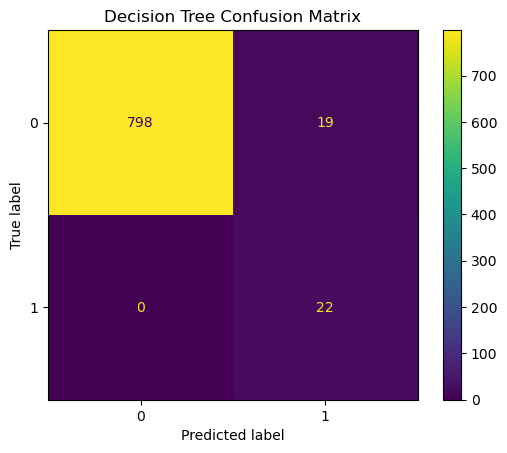

In [249]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tree_predictions
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

### Decision Tree Interpretation

The Decision Tree results show how effectively the model distinguishes between winning and non-winning political party records.

The confusion matrix is particularly useful for identifying false positives and false negatives.

The results should be compared with Logistic Regression to determine whether the Decision Tree provides better identification of the minority winning class.

## 5.8 Random Forest Classifier

Random Forest is an ensemble machine learning algorithm that combines multiple Decision Trees.

Instead of relying on a single tree, Random Forest creates several trees and combines their predictions.

This can improve predictive performance and reduce the risk of overfitting associated with an individual Decision Tree.

In [250]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    class_weight="balanced",
    random_state=42
)

random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [251]:
forest_predictions = random_forest_model.predict(
    X_test
)

In [252]:
forest_accuracy = accuracy_score(
    y_test,
    forest_predictions
)

forest_precision = precision_score(
    y_test,
    forest_predictions,
    zero_division=0
)

forest_recall = recall_score(
    y_test,
    forest_predictions,
    zero_division=0
)

forest_f1 = f1_score(
    y_test,
    forest_predictions,
    zero_division=0
)

print("RANDOM FOREST RESULTS")
print("---------------------")
print("Accuracy:", round(forest_accuracy, 4))
print("Precision:", round(forest_precision, 4))
print("Recall:", round(forest_recall, 4))
print("F1 Score:", round(forest_f1, 4))



RANDOM FOREST RESULTS
---------------------
Accuracy: 0.9809
Precision: 0.5833
Recall: 0.9545
F1 Score: 0.7241


In [253]:
print("RANDOM FOREST CLASSIFICATION REPORT")
print("-----------------------------------")

print(
    classification_report(
        y_test,
        forest_predictions,
        zero_division=0
    )
)

RANDOM FOREST CLASSIFICATION REPORT
-----------------------------------
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       817
           1       0.58      0.95      0.72        22

    accuracy                           0.98       839
   macro avg       0.79      0.97      0.86       839
weighted avg       0.99      0.98      0.98       839



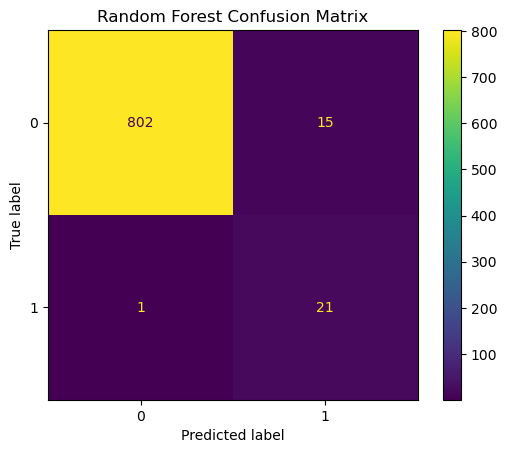

In [254]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    forest_predictions
)

plt.title("Random Forest Confusion Matrix")
plt.show()

### Random Forest Interpretation

The Random Forest model combines predictions from multiple Decision Trees.

Its results are evaluated using the same metrics as Logistic Regression and the Decision Tree model.

Particular attention is given to the F1-score and recall for the winning class because the target variable is imbalanced.

The model results will be compared to determine which algorithm provides the strongest overall performance.

## 5.10 Model Comparison

The three machine learning models are compared using the same evaluation metrics.

Since the dataset contains considerably fewer winning records than non-winning records, accuracy alone should not be used to select the best model.

Precision, recall and F1-score are also considered when evaluating model performance.

In [255]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        forest_accuracy
    ],

    "Precision": [
        logistic_precision,
        tree_precision,
        forest_precision
    ],

    "Recall": [
        logistic_recall,
        tree_recall,
        forest_recall
    ],

    "F1 Score": [
        logistic_f1,
        tree_f1,
        forest_f1
    ]
})

model_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.544696,0.043147,0.772727,0.081731
1,Decision Tree,0.977354,0.536585,1.000000,0.698413
2,Random Forest,0.980930,0.583333,0.954545,0.724138


In [256]:
model_results[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
] = model_results[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].round(4)

model_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.5447,0.0431,0.7727,0.0817
1,Decision Tree,0.9774,0.5366,1.0000,0.6984
2,Random Forest,0.9809,0.5833,0.9545,0.7241


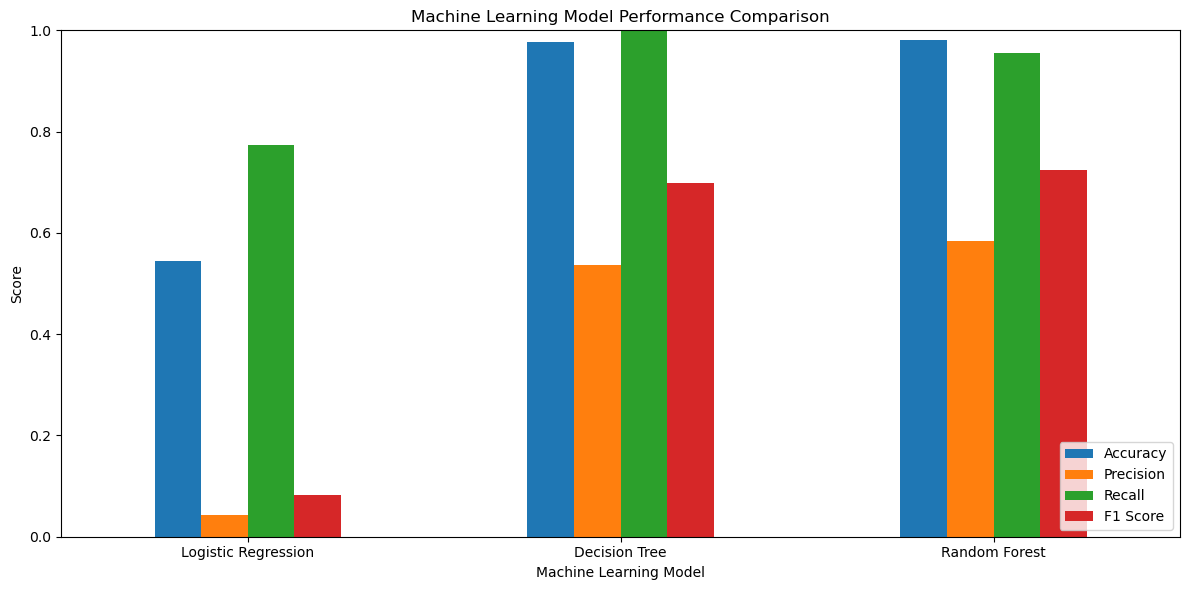

In [257]:
comparison_data = model_results.set_index("Model")

comparison_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(
    loc="lower right"
)

plt.tight_layout()
plt.show()

### Model Comparison Interpretation

The graph compares the performance of Logistic Regression, Decision Tree and Random Forest.

The models are evaluated using accuracy, precision, recall and F1-score.

Because the target variable is imbalanced, the model with the highest accuracy is not automatically considered the best model. Greater attention is given to recall and F1-score because these metrics provide more information about the model's ability to correctly identify winning political party records.

In [258]:
best_model_row = model_results.loc[
    model_results["F1 Score"].idxmax()
]

print("BEST MODEL BASED ON F1 SCORE")
print("----------------------------")

print("Model:", best_model_row["Model"])
print("Accuracy:", best_model_row["Accuracy"])
print("Precision:", best_model_row["Precision"])
print("Recall:", best_model_row["Recall"])
print("F1 Score:", best_model_row["F1 Score"])

BEST MODEL BASED ON F1 SCORE
----------------------------
Model: Random Forest
Accuracy: 0.9809
Precision: 0.5833
Recall: 0.9545
F1 Score: 0.7241


## 5.13 Random Forest Feature Importance

Random Forest can estimate the relative importance of the predictor variables used during model training.

Feature importance helps identify which variables have the greatest influence on the model's predictions.

However, feature importance does not necessarily indicate a causal relationship. It only indicates how useful a variable was to the model when making predictions.

In [259]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
2,PartyEncoded,0.870007
3,WardEncoded,0.052892
0,RegisteredVoters,0.050724
1,NumberOfVotingDistricts,0.026377


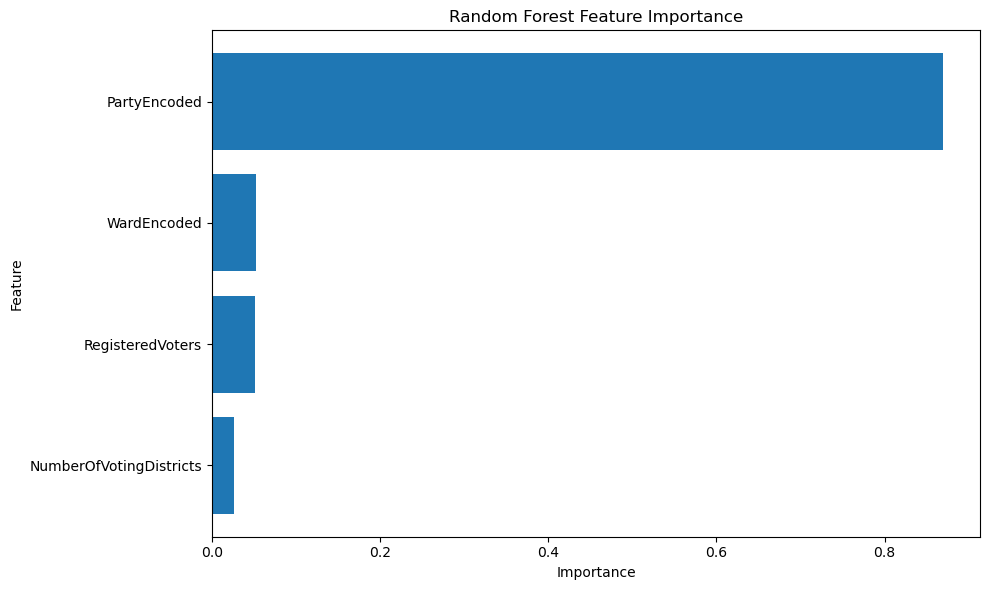

In [260]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Feature Importance Interpretation

The feature importance graph shows which predictor variables contributed most strongly to the Random Forest model.

Features with larger importance values had a greater influence on the model's decisions.

These results should be interpreted carefully because some variables, such as encoded ward and political party identifiers, represent categories rather than continuous measurements of political support.

## 5.14 Baseline Model Comparison

A baseline model provides a simple reference point for evaluating machine learning performance.

Because most records in the dataset represent non-winning political parties, a model that always predicts the majority class could achieve relatively high accuracy without actually learning useful election patterns.

A Dummy Classifier is therefore used as a baseline.

The trained machine learning models should ideally provide better and more meaningful performance than this simple baseline.

In [261]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(
    strategy="most_frequent",
    random_state=42
)

dummy_model.fit(
    X_train,
    y_train
)

dummy_predictions = dummy_model.predict(
    X_test
)

In [262]:
dummy_accuracy = accuracy_score(
    y_test,
    dummy_predictions
)

dummy_precision = precision_score(
    y_test,
    dummy_predictions,
    zero_division=0
)

dummy_recall = recall_score(
    y_test,
    dummy_predictions,
    zero_division=0
)

dummy_f1 = f1_score(
    y_test,
    dummy_predictions,
    zero_division=0
)

print("BASELINE MODEL RESULTS")
print("----------------------")

print("Accuracy:", round(dummy_accuracy, 4))
print("Precision:", round(dummy_precision, 4))
print("Recall:", round(dummy_recall, 4))
print("F1 Score:", round(dummy_f1, 4))

BASELINE MODEL RESULTS
----------------------
Accuracy: 0.9738
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


## 5.15 Machine Learning Evaluation Summary

Three classification algorithms were trained and evaluated: Logistic Regression, Decision Tree and Random Forest.

The models were evaluated using accuracy, precision, recall, F1-score, classification reports and confusion matrices. These multiple evaluation measures were necessary because the Winner target variable contains class imbalance.

A Dummy Classifier was also used as a baseline. This demonstrated why accuracy alone can be misleading when one target class occurs much more frequently than another.

The model comparison provides evidence for selecting the strongest model based on its ability to identify winning political party records rather than simply predicting the majority non-winning class.

Random Forest feature importance was also examined to determine which input variables contributed most strongly to its predictions.

However, the current machine learning experiment has an important limitation. The available dataset represents a limited historical election period, and variables such as encoded party and ward identifiers do not directly measure historical political support.

Therefore, the current models should primarily be interpreted as classification experiments based on the available election dataset rather than definitive forecasts of the 2026 Local Government Election.

A stronger future election forecasting model would require additional historical election data, particularly previous party vote shares and election results across multiple election periods.

# Model Improvement and Final Prediction

After training and comparing the initial machine learning models, the next stage is to improve the selected model.

Random Forest is further optimised using hyperparameter tuning and cross-validation.

The objectives of this section are to:

- Improve the Random Forest model
- Find the best model parameters
- Evaluate the improved model
- Analyse the confusion matrix
- Calculate ROC-AUC
- Examine feature importance
- Generate prediction probabilities
- Identify predicted leading parties by ward
- Compare predicted and actual ward winners
- Save the final trained model

## 6.1 Importing Required Libraries

Additional Scikit-learn tools are required for model optimisation and evaluation.

GridSearchCV is used to test different Random Forest parameter combinations, while StratifiedKFold is used to maintain the distribution of the target classes during cross-validation.

In [263]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

print("Step 6 libraries imported successfully!")

Step 6 libraries imported successfully!


## 6.2 Creating the Random Forest Model

A new Random Forest model is created for optimisation.

Class weights are balanced because the dataset contains considerably more non-winning political party records than winning records.

In [264]:
rf_tuning_model = RandomForestClassifier(
    class_weight="balanced",
    random_state=42
)

print("Random Forest model created.")

Random Forest model created.


## 6.3 Defining Hyperparameters

Hyperparameters control how a machine learning model is constructed.

Different values are tested for:

- Number of Decision Trees
- Maximum tree depth
- Minimum samples required to split a node
- Minimum samples required at a leaf node

Grid Search will determine which combination produces the best F1-score.

In [265]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

print("Parameter grid:")
print(param_grid)

Parameter grid:
{'n_estimators': [100, 200, 300], 'max_depth': [5, 10, None], 'min_samples_split': [2, 5], 'min_samples_leaf': [1, 2]}


## 6.4 Stratified Cross-Validation

Five-fold Stratified Cross-Validation is used during model optimisation.

The training data is divided into five sections. The model is repeatedly trained using four sections and validated using the remaining section.

Stratification helps maintain a similar proportion of winning and non-winning records within each fold.

In [266]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold stratified cross-validation created.")

5-fold stratified cross-validation created.


## 6.5 Random Forest Hyperparameter Tuning

GridSearchCV tests different combinations of Random Forest hyperparameters.

F1-score is used to select the best model because the target variable is imbalanced and accuracy alone may provide a misleading representation of model performance.

In [267]:
grid_search = GridSearchCV(
    estimator=rf_tuning_model,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("Starting Grid Search...")

grid_search.fit(
    X_train,
    y_train
)

print("Grid Search completed!")

Starting Grid Search...
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Grid Search completed!


## 6.6 Best Model Parameters

After testing the different parameter combinations, Grid Search identifies the combination that achieved the highest average F1-score during cross-validation.

In [268]:
print("BEST PARAMETERS")
print("----------------")

print(grid_search.best_params_)

print(
    "\nBest Cross-Validation F1 Score:",
    round(grid_search.best_score_, 4)
)

BEST PARAMETERS
----------------
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}

Best Cross-Validation F1 Score: 0.5576


In [269]:
best_rf_model = grid_search.best_estimator_

print("Best Random Forest model selected!")

Best Random Forest model selected!


## 6.7 Making Predictions

The optimised Random Forest model is applied to the testing dataset.

Two outputs are generated:

- Predicted class, indicating winner or non-winner
- Prediction probability, indicating the model's estimated probability that a record belongs to the winning class

In [270]:
best_predictions = best_rf_model.predict(
    X_test
)

best_probabilities = best_rf_model.predict_proba(
    X_test
)[:, 1]

print("Predictions completed!")

Predictions completed!


## 6.8 Evaluating the Optimised Model

The optimised Random Forest model is evaluated using accuracy, precision, recall, F1-score and ROC-AUC.

Multiple evaluation metrics are necessary because the target classes are imbalanced.

In [271]:
best_accuracy = accuracy_score(
    y_test,
    best_predictions
)

best_precision = precision_score(
    y_test,
    best_predictions,
    zero_division=0
)

best_recall = recall_score(
    y_test,
    best_predictions,
    zero_division=0
)

best_f1 = f1_score(
    y_test,
    best_predictions,
    zero_division=0
)

best_auc = roc_auc_score(
    y_test,
    best_probabilities
)

print("TUNED RANDOM FOREST RESULTS")
print("---------------------------")

print("Accuracy:", round(best_accuracy, 4))
print("Precision:", round(best_precision, 4))
print("Recall:", round(best_recall, 4))
print("F1 Score:", round(best_f1, 4))
print("ROC-AUC:", round(best_auc, 4))

TUNED RANDOM FOREST RESULTS
---------------------------
Accuracy: 0.9821
Precision: 0.6
Recall: 0.9545
F1 Score: 0.7368
ROC-AUC: 0.9955


In [272]:
print("CLASSIFICATION REPORT")
print("---------------------")

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=[
            "Non-Winner",
            "Winner"
        ],
        zero_division=0
    )
)

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

  Non-Winner       1.00      0.98      0.99       817
      Winner       0.60      0.95      0.74        22

    accuracy                           0.98       839
   macro avg       0.80      0.97      0.86       839
weighted avg       0.99      0.98      0.98       839



### Interpretation

The classification report provides detailed performance information for both non-winning and winning political party records.

Particular attention should be given to the precision, recall and F1-score of the Winner class because this is the minority class that the model is attempting to identify correctly.

## 6.9 Confusion Matrix

The confusion matrix provides a visual summary of correct and incorrect predictions.

It shows the number of:

- True Negatives
- False Positives
- False Negatives
- True Positives

A strong model should correctly identify both non-winning and winning records.

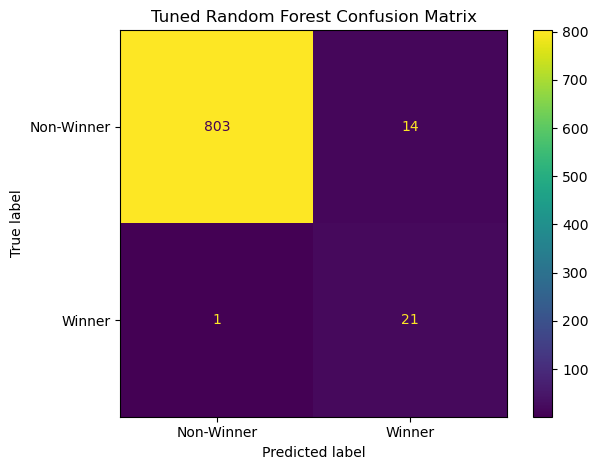

In [273]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=[
        "Non-Winner",
        "Winner"
    ]
)

plt.title("Tuned Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

## 6.10 ROC Curve and ROC-AUC

The Receiver Operating Characteristic (ROC) curve evaluates the model's ability to distinguish between the two target classes at different classification thresholds.

The ROC-AUC score summarises this performance.

A larger ROC-AUC value generally indicates better discrimination between winning and non-winning records.

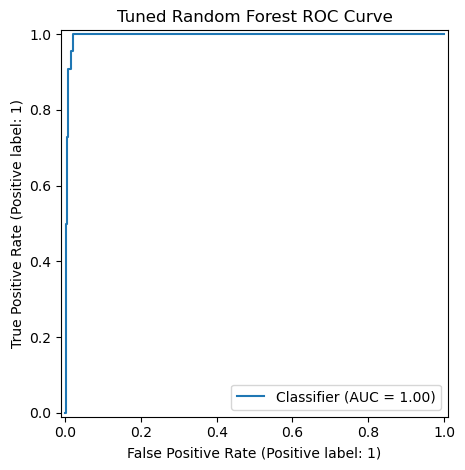

ROC-AUC Score: 0.9955


In [274]:
RocCurveDisplay.from_predictions(
    y_test,
    best_probabilities
)

plt.title("Tuned Random Forest ROC Curve")
plt.tight_layout()
plt.show()

print(
    "ROC-AUC Score:",
    round(best_auc, 4)
)

## 6.11 Final Cross-Validation

The best Random Forest model is evaluated again using five-fold cross-validation.

This helps determine whether model performance remains relatively consistent across different sections of the training data.

In [275]:
cv_scores = cross_val_score(
    best_rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

print("Cross-Validation F1 Scores:")
print(np.round(cv_scores, 4))

print(
    "\nMean F1 Score:",
    round(cv_scores.mean(), 4)
)

print(
    "Standard Deviation:",
    round(cv_scores.std(), 4)
)

Cross-Validation F1 Scores:
[0.4783 0.5238 0.6471 0.4878 0.6512]

Mean F1 Score: 0.5576
Standard Deviation: 0.0762


## 6.12 Feature Importance

Random Forest provides information about the relative importance of the features used during prediction.

Feature importance indicates which variables were most useful to the model.

However, feature importance should not be interpreted as evidence that a variable directly causes an election outcome.

In [276]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
2,PartyEncoded,0.872026
0,RegisteredVoters,0.051110
3,WardEncoded,0.050478
1,NumberOfVotingDistricts,0.026386


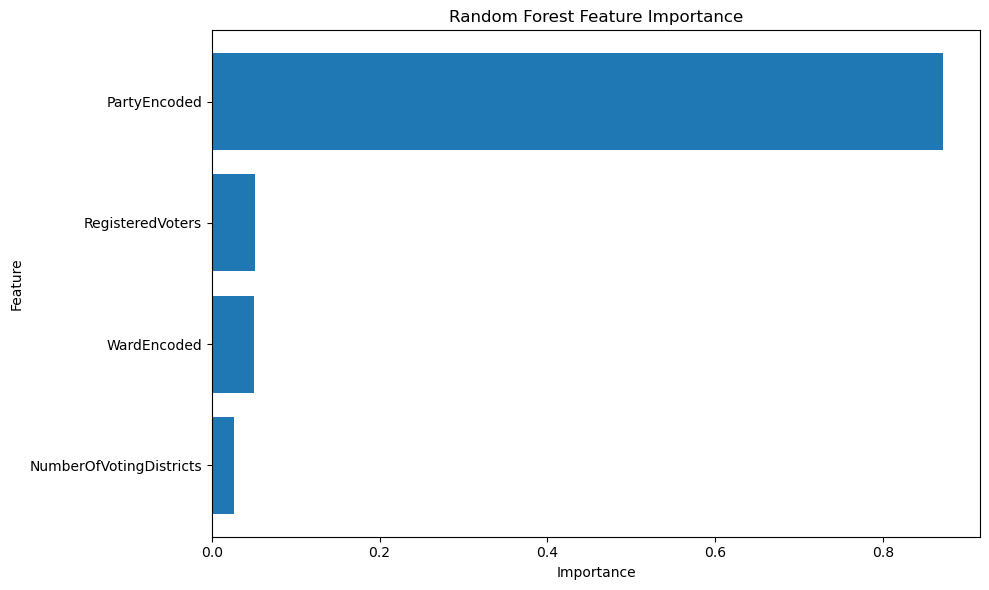

In [289]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## 6.13 Generating Predictions for the Election Dataset

The optimised model is now applied to the complete prepared machine learning dataset.

A prediction and winner probability are generated for each political party within each ward.

In [290]:
full_X = ward_party_ml[
    [
        "RegisteredVoters",
        "NumberOfVotingDistricts",
        "PartyEncoded",
        "WardEncoded"
    ]
]

ward_party_ml["PredictedWinner"] = (
    best_rf_model.predict(full_X)
)

ward_party_ml["WinnerProbability"] = (
    best_rf_model.predict_proba(full_X)[:, 1]
)

ward_party_ml[
    [
        "Ward",
        "PartyName",
        "TotalValidVotes",
        "Winner",
        "PredictedWinner",
        "WinnerProbability"
    ]
].head(20)

,Ward,PartyName,TotalValidVotes,Winner,PredictedWinner,WinnerProbability
0,Ward 59500001,ABANTU BATHO CONGRESS,304,0,0,0.009565
1,Ward 59500001,ACADEMIC CONGRESS UNION,3,0,0,0.009565
2,Ward 59500001,ACTIONSA,16,0,0,0.009565
3,Ward 59500001,ACTIVISTS MOVEMENT OF SOUTH AFRICA,2,0,0,0.009565
4,Ward 59500001,ADVANCED DYNAMIC ALLIANCE,3,0,0,0.009565
5,Ward 59500001,AFRICA RESTORATION ALLIANCE,3,0,0,0.009565
6,Ward 59500001,AFRICAN CHRISTIAN DEMOCRATIC PARTY,16,0,0,0.009565
7,Ward 59500001,AFRICAN DEMOCRATIC CHANGE,0,0,0,0.009565
8,Ward 59500001,AFRICAN MANTUNGWA COMMUNITY,17,0,0,0.019300
9,Ward 59500001,AFRICAN NATIONAL CONGRESS,9152,1,1,0.859680


## 6.14 Predicted Leading Political Party by Ward

Each political party receives a predicted winner probability.

Within each ward, the political party with the highest predicted probability is selected as the model's predicted leading party.

This produces one predicted leading political party for each ward.

In [291]:
predicted_ward_winners = ward_party_ml.loc[
    ward_party_ml.groupby("Ward")[
        "WinnerProbability"
    ].idxmax()
]

predicted_ward_winners = predicted_ward_winners[
    [
        "Ward",
        "PartyName",
        "WinnerProbability"
    ]
].sort_values("Ward").reset_index(drop=True)

predicted_ward_winners.head(20)

,Ward,PartyName,WinnerProbability
0,Ward 59500001,AFRICAN NATIONAL CONGRESS,0.859680
1,Ward 59500002,AFRICAN NATIONAL CONGRESS,0.817145
2,Ward 59500003,AFRICAN NATIONAL CONGRESS,0.807800
3,Ward 59500004,AFRICAN NATIONAL CONGRESS,0.849352
4,Ward 59500005,AFRICAN NATIONAL CONGRESS,0.937462
5,Ward 59500006,AFRICAN NATIONAL CONGRESS,0.959280
6,Ward 59500007,AFRICAN NATIONAL CONGRESS,0.952980
7,Ward 59500008,AFRICAN NATIONAL CONGRESS,0.874862
8,Ward 59500009,AFRICAN NATIONAL CONGRESS,0.791031
9,Ward 59500010,DEMOCRATIC ALLIANCE,0.700178


In [292]:
predicted_party_wins = (
    predicted_ward_winners["PartyName"]
    .value_counts()
)

print("Predicted Ward Leaders:")
print(predicted_party_wins)

Predicted Ward Leaders:
PartyName
AFRICAN NATIONAL CONGRESS    79
DEMOCRATIC ALLIANCE          32
Name: count, dtype: int64


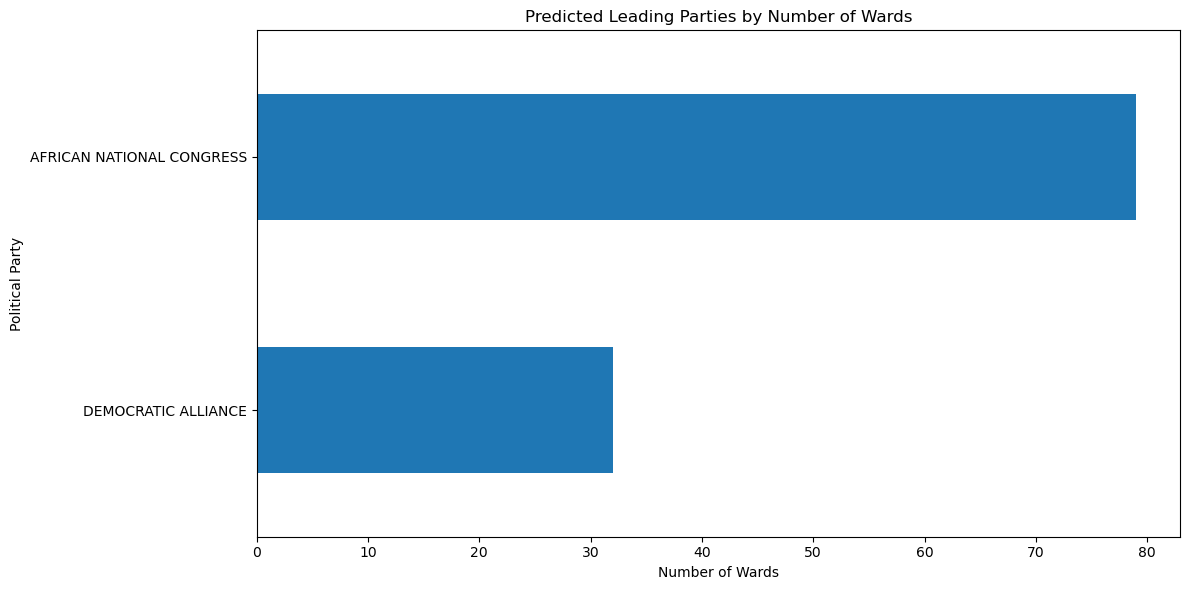

In [293]:
plt.figure(figsize=(12, 6))

predicted_party_wins.sort_values().plot(
    kind="barh"
)

plt.title(
    "Predicted Leading Parties by Number of Wards"
)

plt.xlabel("Number of Wards")
plt.ylabel("Political Party")

plt.tight_layout()
plt.show()

## 6.15 Comparing Actual and Predicted Ward Leaders

The predicted ward leaders are compared with the actual historical leading political parties.

This provides a more election-focused evaluation of whether the model correctly identifies the leading party within individual wards.

In [282]:
actual_ward_winners = ward_party_ml[
    ward_party_ml["Winner"] == 1
][
    ["Ward", "PartyName"]
].copy()

actual_ward_winners = actual_ward_winners.rename(
    columns={
        "PartyName": "ActualParty"
    }
)

comparison = actual_ward_winners.merge(
    predicted_ward_winners,
    on="Ward",
    how="left"
)

comparison = comparison.rename(
    columns={
        "PartyName": "PredictedParty"
    }
)

comparison["CorrectPrediction"] = (
    comparison["ActualParty"]
    == comparison["PredictedParty"]
)

comparison.head(20)

,Ward,ActualParty,PredictedParty,WinnerProbability,CorrectPrediction
0,Ward 59500001,AFRICAN NATIONAL CONGRESS,AFRICAN NATIONAL CONGRESS,0.859680,True
1,Ward 59500002,AFRICAN NATIONAL CONGRESS,AFRICAN NATIONAL CONGRESS,0.817145,True
2,Ward 59500003,AFRICAN NATIONAL CONGRESS,AFRICAN NATIONAL CONGRESS,0.807800,True
3,Ward 59500004,AFRICAN NATIONAL CONGRESS,AFRICAN NATIONAL CONGRESS,0.849352,True
4,Ward 59500005,AFRICAN NATIONAL CONGRESS,AFRICAN NATIONAL CONGRESS,0.937462,True
5,Ward 59500006,AFRICAN NATIONAL CONGRESS,AFRICAN NATIONAL CONGRESS,0.959280,True
6,Ward 59500007,AFRICAN NATIONAL CONGRESS,AFRICAN NATIONAL CONGRESS,0.952980,True
7,Ward 59500008,AFRICAN NATIONAL CONGRESS,AFRICAN NATIONAL CONGRESS,0.874862,True
8,Ward 59500009,DEMOCRATIC ALLIANCE,AFRICAN NATIONAL CONGRESS,0.791031,False
9,Ward 59500010,DEMOCRATIC ALLIANCE,DEMOCRATIC ALLIANCE,0.700178,True


In [283]:
ward_accuracy = (
    comparison["CorrectPrediction"].mean()
)

print(
    "Ward-Level Winner Accuracy:",
    round(ward_accuracy * 100, 2),
    "%"
)

Ward-Level Winner Accuracy: 87.39 %


In [284]:
incorrect_wards = comparison[
    comparison["CorrectPrediction"] == False
]

print(
    "Number of incorrectly predicted wards:",
    len(incorrect_wards)
)

incorrect_wards.head(20)

Number of incorrectly predicted wards: 14


,Ward,ActualParty,PredictedParty,WinnerProbability,CorrectPrediction
8,Ward 59500009,DEMOCRATIC ALLIANCE,AFRICAN NATIONAL CONGRESS,0.791031,False
17,Ward 59500018,DEMOCRATIC ALLIANCE,AFRICAN NATIONAL CONGRESS,0.680200,False
35,Ward 59500036,DEMOCRATIC ALLIANCE,AFRICAN NATIONAL CONGRESS,0.668444,False
38,Ward 59500039,INKATHA FREEDOM PARTY,AFRICAN NATIONAL CONGRESS,0.681471,False
47,Ward 59500048,DEMOCRATIC ALLIANCE,AFRICAN NATIONAL CONGRESS,0.813207,False
51,Ward 59500052,DEMOCRATIC ALLIANCE,AFRICAN NATIONAL CONGRESS,0.870780,False
54,Ward 59500055,AFRICAN NATIONAL CONGRESS,DEMOCRATIC ALLIANCE,0.789403,False
60,Ward 59500061,DEMOCRATIC ALLIANCE,AFRICAN NATIONAL CONGRESS,0.776595,False
61,Ward 59500062,AFRICAN NATIONAL CONGRESS,DEMOCRATIC ALLIANCE,0.866667,False
71,Ward 59500072,AFRICAN NATIONAL CONGRESS,DEMOCRATIC ALLIANCE,0.891741,False


## 6.16 Final Model Performance Summary

A final summary table is created to present the major evaluation metrics of the optimised Random Forest model.

This provides a concise overview of the model's performance.

In [285]:
final_model_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Cross Validation F1",
        "Ward-Level Accuracy"
    ],

    "Score": [
        best_accuracy,
        best_precision,
        best_recall,
        best_f1,
        best_auc,
        cv_scores.mean(),
        ward_accuracy
    ]
})

final_model_summary["Score"] = (
    final_model_summary["Score"]
    .round(4)
)

final_model_summary

,Metric,Score
0,Accuracy,0.9821
1,Precision,0.6000
2,Recall,0.9545
3,F1 Score,0.7368
4,ROC-AUC,0.9955
5,Cross Validation F1,0.5576
6,Ward-Level Accuracy,0.8739


## 6.17 Saving the Machine Learning Model

The final Random Forest model and categorical encoders are saved.

Saving these objects allows them to be loaded by the Streamlit application without retraining the model every time the dashboard starts.

In [286]:
joblib.dump(
    best_rf_model,
    "best_random_forest_model.pkl"
)

joblib.dump(
    party_encoder,
    "party_encoder.pkl"
)

joblib.dump(
    ward_encoder,
    "ward_encoder.pkl"
)

print("Model and encoders saved successfully!")

Model and encoders saved successfully!


In [288]:
predicted_ward_winners.to_csv(
    "predicted_ward_winners.csv",
    index=False
)

comparison.to_csv(
    "actual_vs_predicted_winners.csv",
    index=False
)

final_model_summary.to_csv(
    "model_evaluation_summary.csv",
    index=False
)

print("Prediction results saved successfully!")

Prediction results saved successfully!


## 6.18 Step 6 Conclusion

The Random Forest model was improved using hyperparameter tuning and five-fold Stratified Cross-Validation.

Grid Search was used to identify the combination of Random Forest parameters that produced the strongest F1-score.

The optimised model was evaluated using accuracy, precision, recall, F1-score, ROC-AUC, classification reports and a confusion matrix.

Prediction probabilities were then generated for political parties within each ward. The party with the highest predicted probability was selected as the predicted leading party for that ward.

The predicted ward leaders were compared with the actual historical election results to calculate ward-level prediction accuracy.

Feature importance was also examined to understand which variables contributed most strongly to the Random Forest predictions.

Although this analysis demonstrates the application of machine learning to election data, the predictions should not be interpreted as definitive predictions for the 2026 Local Government Election.

A reliable future election forecast would require multiple historical election periods and additional features such as previous party vote share, historical ward performance, voter turnout trends and changes in political support.

Therefore, the current model provides a foundation for election classification and future predictive analysis rather than a guaranteed forecast of future election results.